# LRM51 transcriptomic predictor for PD-1/PD-L1 immunotherapy response

This notebook prepares the expression matrix, applies CPM normalization, evaluates a logistic regression model, interprets the selected genes with SHAP, and summarizes the final 51-gene model performance.

> **Note:** Update the file paths in the data-loading section before running the notebook outside the original Google Colab environment.


### Reproducibility notes

- Keep all random seeds fixed when reproducing model performance.
- Apply oversampling only within the training data.
- Do not recompute normalization parameters using validation or test labels.


## 1. Environment setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.feature_selection as fs
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
from sklearn import cluster, datasets, mixture
from sklearn.cluster import KMeans
from itertools import cycle, islice
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.metrics import recall_score
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from statistics import mean, stdev
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import (
    RidgeClassifier, SGDClassifier, PassiveAggressiveClassifier, Perceptron
)
from sklearn.svm import SVC, NuSVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from lightgbm import LGBMClassifier
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import zscore
from imblearn.over_sampling import SMOTE, ADASYN
from collections import Counter
from sklearn.manifold import TSNE
import itertools
from sklearn.metrics import roc_auc_score, f1_score


In [ ]:
import sys
import sklearn
import imblearn
import shap
import pandas as pd
import numpy as np
print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("shap:", shap.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
shap: 0.54.1
pandas: 2.2.3
numpy: 2.1.3


In [ ]:
!pip install shap
import shap

In [ ]:
!pip install scikit-posthocs
import scikit_posthocs as sp

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import matplotlib.font_manager as fm

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13
})

## 2. Load count matrices and labels

In [ ]:
# Raw count matrix
raw_counts = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AUNA/crudaCompleta.csv", header=0, index_col=0, sep=",")
raw_counts = raw_counts.dropna()
raw_counts = raw_counts.astype("float")
raw_counts = raw_counts.transpose()
raw_counts

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned/SRR7344546,0.0,11.0,3.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344548,0.0,15.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344554,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344564,0.0,451.0,26.0,0.0,0.0,0.0,0.0,0.0,20.0,177.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344565,0.0,341.0,21.0,1.0,0.0,0.0,0.0,0.0,17.0,67.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.0,1468.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1713.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,17.0,1619.0,2.0,0.0,0.0,0.0,8.0,0.0,1.0,4758.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.0,1153.0,1.0,0.0,0.0,2.0,2.0,0.0,4.0,1232.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.0,488.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,4580.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
raw_counts = raw_counts.drop(index=['ERR2498029', 'EGAR00001766803']) # Remove samples with artifacts in the gene-read density curve
raw_counts

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned/SRR7344546,0.0,11.0,3.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344548,0.0,15.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344554,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344564,0.0,451.0,26.0,0.0,0.0,0.0,0.0,0.0,20.0,177.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned/SRR7344565,0.0,341.0,21.0,1.0,0.0,0.0,0.0,0.0,17.0,67.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.0,1468.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1713.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,17.0,1619.0,2.0,0.0,0.0,0.0,8.0,0.0,1.0,4758.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.0,1153.0,1.0,0.0,0.0,2.0,2.0,0.0,4.0,1232.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.0,488.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,4580.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Load the first clinical metadata table
clinical_metadata = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AUNA/ListaPacientes2912023-3.csv")
clinical_metadata = clinical_metadata[clinical_metadata['run_accession'] != 'EGAR00001766803']
y = clinical_metadata['Best RECIST response']
y = np.array([0 if (value.strip() == 'PD' or value.strip() == 'SD' or value.strip() == 'NR') else 1 for value in y])
clinical_metadata['Best RECIST response'] = y
clinical_metadata['Best RECIST response'].value_counts()
clinical_metadata

,run_accession,Base,Best RECIST response,Tipo
0,gned/SRR7344546,Auslander,1,Melanoma
1,gned/SRR7344548,Auslander,0,Melanoma
2,gned/SRR7344554,Auslander,0,Melanoma
3,gned/SRR7344564,Auslander,0,Melanoma
4,gned/SRR7344565,Auslander,0,Melanoma
...,...,...,...,...
541,gned/SRR5088920,RIAZ,0,Melanoma
542,gned/SRR5088922,RIAZ,0,Melanoma
543,gned/SRR5088924,RIAZ,1,Melanoma
544,gned/SRR5088926,RIAZ,0,Melanoma


In [ ]:
# Load the second clinical metadata table
clinical_metadata_val = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AUNA/listaPacientesVal.csv")
# Remove the sample flagged as an artifact
clinical_metadata_val = clinical_metadata_val[clinical_metadata_val['run_accession'] != 'ERR2498029']
y2 = clinical_metadata_val['Best RECIST response']
y2 = np.array([0 if (value.strip() == 'PD' or value.strip() == 'SD' or value.strip() == 'NR') else 1 for value in y2])
clinical_metadata_val['Best RECIST response'] = y2
clinical_metadata_val['Best RECIST response'].value_counts()
clinical_metadata_val

,run_accession,Base,Best RECIST response
0,SRR8526717,CHO,0
1,SRR8526718,CHO,1
2,SRR8526719,CHO,0
3,SRR8526720,CHO,0
4,SRR8526721,CHO,1
...,...,...,...
65,ERR2208953,GIDE,1
66,ERR2208954,GIDE,1
67,ERR2208967,GIDE,1
68,ERR2208973,GIDE,0


In [ ]:
clinical_metadata_val["Tipo"] = clinical_metadata_val["Base"].apply(lambda x: "lung" if x == "CHO" else "Gastrico" if x == "KIM2" else "Melanoma")
clinical_metadata_val

,run_accession,Base,Best RECIST response,Tipo
0,SRR8526717,CHO,0,lung
1,SRR8526718,CHO,1,lung
2,SRR8526719,CHO,0,lung
3,SRR8526720,CHO,0,lung
4,SRR8526721,CHO,1,lung
...,...,...,...,...
65,ERR2208953,GIDE,1,Melanoma
66,ERR2208954,GIDE,1,Melanoma
67,ERR2208967,GIDE,1,Melanoma
68,ERR2208973,GIDE,0,Melanoma


In [ ]:
# Merge both clinical metadata tables
clinical_metadata = pd.concat([clinical_metadata, clinical_metadata_val])
clinical_metadata

,run_accession,Base,Best RECIST response,Tipo
0,gned/SRR7344546,Auslander,1,Melanoma
1,gned/SRR7344548,Auslander,0,Melanoma
2,gned/SRR7344554,Auslander,0,Melanoma
3,gned/SRR7344564,Auslander,0,Melanoma
4,gned/SRR7344565,Auslander,0,Melanoma
...,...,...,...,...
65,ERR2208953,GIDE,1,Melanoma
66,ERR2208954,GIDE,1,Melanoma
67,ERR2208967,GIDE,1,Melanoma
68,ERR2208973,GIDE,0,Melanoma


In [ ]:
# Merge response labels
y = np.concatenate((y, y2))
y

array([1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,

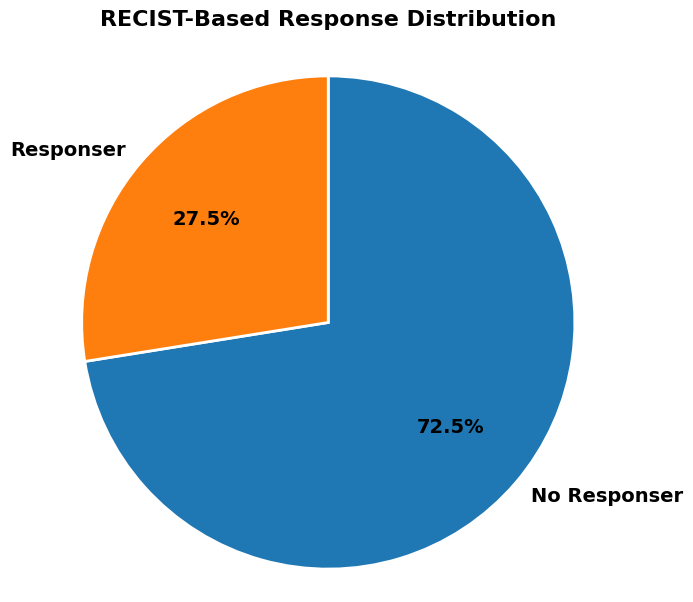

In [ ]:
import matplotlib.pyplot as plt

# ==========================
# Publication-quality plotting settings
# ==========================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,          # Keep labels readable for publication figures
    'axes.titlesize': 16,
    'axes.titleweight': 'bold'
})

# Crear un diccionario para mapear valores binarios a etiquetas
label_mapping = {
    0: 'No Responser',
    1: 'Responser'
}

# Contar valores
value_counts = clinical_metadata['Best RECIST response'].value_counts()

# Reemplazar números por etiquetas
labels = [label_mapping[val] for val in value_counts.index]

# Create figure (más grande para publicación)
fig, ax = plt.subplots(figsize=(7,7))

# Pie chart
wedges, texts, autotexts = ax.pie(
    value_counts,
    labels=labels,
    autopct='%.1f%%',
    startangle=90,
    counterclock=False,
    labeldistance=1.08,
    pctdistance=0.65,
    wedgeprops=dict(
        edgecolor='white',
        linewidth=2
    ),
    textprops=dict(
        fontsize=14,
        fontweight='bold'
    )
)

# Formato de los porcentajes
for autotext in autotexts:
    autotext.set_fontsize(14)
    autotext.set_fontweight('bold')
    autotext.set_color('black')

# Formato de las etiquetas
for text in texts:
    text.set_fontsize(14)
    text.set_fontweight('bold')

# Título
ax.set_title(
    "RECIST-Based Response Distribution",
    fontsize=16,
    fontweight='bold',
    pad=20
)

# Mantener forma circular
ax.axis('equal')

# Save figure en TIFF 600 dpi
plt.savefig(
    "RECIST_Response_Distribution.tiff",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "raw"}
)

plt.show()

In [ ]:
np.array_equal(raw_counts.index, clinical_metadata['run_accession']	)

True

In [ ]:
# Replace slashes in sample identifiers to match downstream tables
raw_counts.index = raw_counts.index.str.replace('/', '.')
raw_counts

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.0,11.0,3.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.0,15.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.0,451.0,26.0,0.0,0.0,0.0,0.0,0.0,20.0,177.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.0,341.0,21.0,1.0,0.0,0.0,0.0,0.0,17.0,67.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.0,1468.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1713.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,17.0,1619.0,2.0,0.0,0.0,0.0,8.0,0.0,1.0,4758.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.0,1153.0,1.0,0.0,0.0,2.0,2.0,0.0,4.0,1232.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.0,488.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,4580.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:

# Harmonize cancer type labels
cancer_type_corrections = {
    "thymic": "Thymic",
    "Gastrico": "Gastric",
    "lung": "Lung",
    "oral": "Oral",
    "Urothelial": "Urothelial",
    # Agrega aquí otras cancer_type_corrections necesarias
}

# Aplicar las cancer_type_corrections
clinical_metadata["Tipo"] = clinical_metadata["Tipo"].replace(cancer_type_corrections)

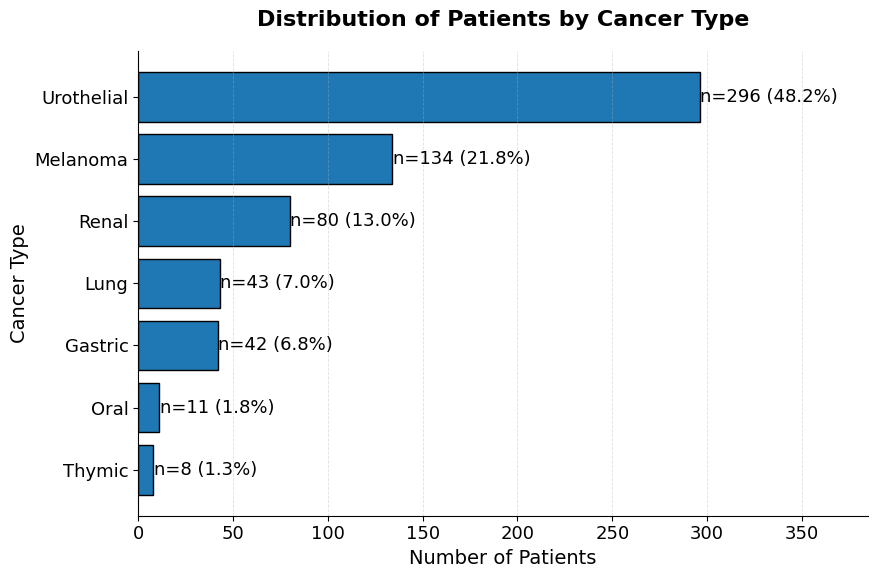

In [ ]:
import matplotlib.pyplot as plt

# ==========================
# Publication-quality settings
# ==========================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13
})

# Count patients by cancer type (ordered from highest to lowest frequency)
value_counts = clinical_metadata['Tipo'].value_counts().sort_values(ascending=False)

# Calculate percentages
percentages = value_counts / value_counts.sum() * 100

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

# Horizontal bar plot
bars = ax.barh(
    value_counts.index,
    value_counts.values,
    edgecolor='black',
    linewidth=1.0
)

# Highest frequency at the top
ax.invert_yaxis()

# Add sample size and percentage
for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(
        width + 0.3,
        bar.get_y() + bar.get_height()/2,
        f'n={int(width)} ({percentages.iloc[i]:.1f}%)',
        va='center',
        ha='left',
        fontsize=13
    )

# Labels and title
ax.set_xlabel("Number of Patients")
ax.set_ylabel("Cancer Type")
ax.set_title(
    "Distribution of Patients by Cancer Type",
    pad=18
)

# Add some extra space for labels
ax.set_xlim(0, value_counts.max() * 1.30)

# Light grid
ax.grid(
    axis='x',
    linestyle='--',
    linewidth=0.6,
    alpha=0.4
)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Optimize layout
plt.tight_layout()

# Save as TIFF (600 dpi)
plt.savefig(
    "Cancer_Type_Distribution.tiff",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "raw"}
)

plt.show()

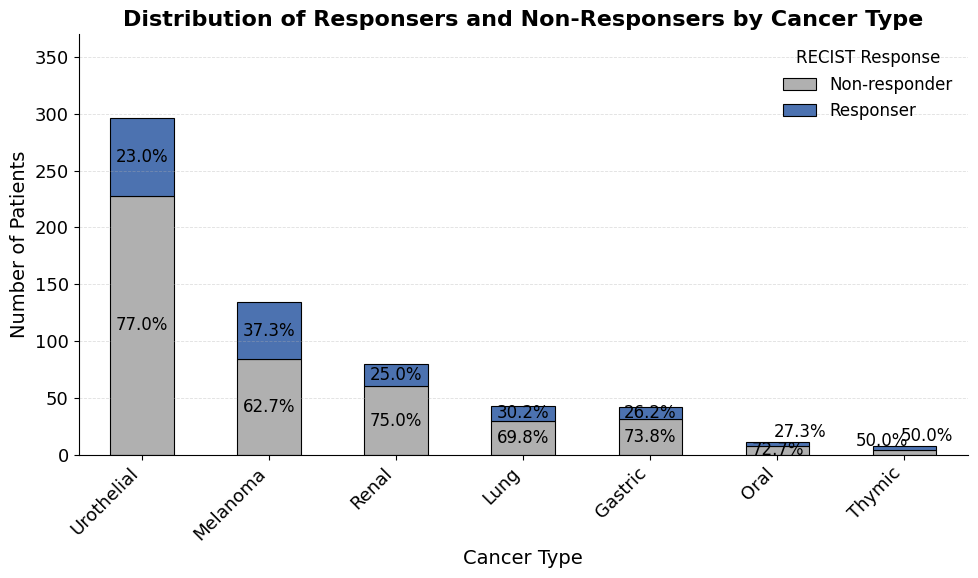

In [ ]:
import matplotlib.pyplot as plt

# ==========================
# Publication-quality settings
# ==========================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'legend.title_fontsize': 12
})

# Ensure response is numeric
clinical_metadata['Best RECIST response'] = clinical_metadata['Best RECIST response'].astype(int)

# Count patients by cancer type and response
conteo = (
clinical_metadata
    .groupby(['Tipo', 'Best RECIST response'])
    .size()
    .unstack(fill_value=0)
)

# Ensure both categories exist
for col in [0, 1]:
    if col not in conteo.columns:
        conteo[col] = 0

conteo = conteo[[0, 1]]

# Sort by total number of patients
conteo = conteo.loc[
    conteo.sum(axis=1).sort_values(ascending=False).index
]

# Percentages within each cancer type
porcentajes = conteo.div(conteo.sum(axis=1), axis=0) * 100

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Sobriety colors
colors = ['#B0B0B0', '#4C72B0']

# Plot
conteo.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor='black',
    linewidth=0.8
)

# Add percentage labels
for i, cancer_type in enumerate(conteo.index):
    cumulative = 0

    for response in [0, 1]:
        count = conteo.loc[cancer_type, response]
        pct = porcentajes.loc[cancer_type, response]

        if count > 0:

            if count >= 5:
                # Label inside large segments
                ax.text(
                    i,
                    cumulative + count / 2,
                    f'{pct:.1f}%',
                    ha='center',
                    va='center',
                    fontsize=12
                )
            else:
                # Label outside small segments with horizontal offset
                x_offset = -0.18 if response == 0 else 0.18
                y_offset = 0.30 if response == 0 else 0.80

                ax.text(
                    i + x_offset,
                    cumulative + count + y_offset,
                    f'{pct:.1f}%',
                    ha='center',
                    va='bottom',
                    fontsize=12
                )

        cumulative += count

# Labels and title
ax.set_xlabel("Cancer Type")
ax.set_ylabel("Number of Patients")
ax.set_title("Distribution of Responsers and Non-Responsers by Cancer Type")

# Legend
ax.legend(
    ["Non-responder", "Responser"],
    title="RECIST Response",
    frameon=False,
    loc='upper right'
)

# X-axis labels
plt.xticks(rotation=45, ha='right')

# Grid
ax.grid(
    axis='y',
    linestyle='--',
    linewidth=0.6,
    alpha=0.4
)

# Remove borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# More vertical room
ax.set_ylim(0, conteo.sum(axis=1).max() * 1.25)

plt.tight_layout()

# Save as TIFF
plt.savefig(
    "Responsers_by_Cancer_Type.tiff",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "raw"}
)

plt.show()

## 3. Define the 51-gene panel

In [ ]:
selected_genes =['SFTPC',
 'CSRP3',
 'LINC00431',
 'MAP4K1',
 'MAGEA10',
 'CXCL10',
 'PKD1L2',
 'SLC6A12',
 'AATF',
 'PGBD2',
 'EPHA8',
 'TXLNGY',
 'LOC124904611',
 'PDIK1L',
 'PTX4',
 'LINC00518',
 'JAKMIP1',
 'SH2D5',
 'REXO5',
 'LOC124903104',
 'MIR604',
 'PAGE5',
 'QRSL1',
 'EOMES',
 'LOC124900759',
 'CYP2S1',
 'CCDC140',
 'LOC124909366',
 'LOC124900511',
 'RWDD2B',
 'LOC124906091',
 'KCNC2',
 'LOC102724334',
 'HOXD1',
 'LIF',
 'RTP5',
 'LOC642131',
 'LOC107985745',
 'ARHGEF35-AS1',
 'KASH5',
 'LOC124901738',
 'DPYSL5',
 'GML',
 'FAM180A',
 'PSME1',
 'ITGAE',
 'LOC101926984',
 'SCG2',
 'RNU6-9',
 'RANGRF',
 'LOC101927723',
 'LRFN4',
 'TLX1',
 'LMBRD2',
 'LOC105372273',
 'LOC644277',
 'MIR542',
 'MEST',
 'CREB3L3',
 'NEUROG2',
 'GRB10',
 'ANKRD18DP',
 'RDM1',
 'TRMT1L',
 'LOC124904912',
 'NEUROG2-AS1',
 'MUC15',
 'LOC105372521',
 'MYADML2',
 'LOC124908054',
 'KLHL29',
 'LOC105370964',
 'LOC105374618',
 'EGR1',
 'RIMBP3B',
 'TRBV11-3',
 'AMN1',
 'GPATCH1', 'AATF',     'LCMT1',    'TXLNGY',
        'GALNT1',  'CEP89', 'LMBRD2', 'GRB10', 'PARP14','AKR1E2', 'PRSS12', 'ANKRD27', 'NSMF',
        'EDC3', 'MAGEA10', 'PAX3', 'MAP4K1', 'COL17A1', 'UBALD2',
       'KLHL29',  'ZSCAN2', 'NACAD', 'LOC102724159',
       'TRMT1L', 'DPYSL5',  'BRF2', 'AP1AR', 'ST8SIA6', 'SIM1',
       'MALL',  'ITGAE',  'MEST', 'HOXC10', 'COL23A1',
       'RDH11', 'RNASEH2A', 'PKD1L2', 'B4GALNT3', 'NR1D2',
      'SLC34A2', 'TVP23B', 'KLRC1', 'SST','PITPNM2', 'BIRC2', 'SLIT2',
       'ARL4C', 'CXCL9', 'CTAGE15', 'ZNF649', 'CPNE8',
       'SFTPC', 'FAT4', 'PM20D1', 'PERP',  'PAPLN', 'SLC6A12',
       'BICC1',  'NHS' , 'CSRP3']


In [ ]:
#dejar elementos únicos en selected_genes
selected_genes = list(set(selected_genes))
#numero de elementos en selected_genes
len(selected_genes)

122

In [ ]:
expression_matrix = raw_counts.copy()
expression_matrix

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.0,11.0,3.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.0,15.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.0,451.0,26.0,0.0,0.0,0.0,0.0,0.0,20.0,177.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.0,341.0,21.0,1.0,0.0,0.0,0.0,0.0,17.0,67.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.0,1468.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1713.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,17.0,1619.0,2.0,0.0,0.0,0.0,8.0,0.0,1.0,4758.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.0,1153.0,1.0,0.0,0.0,2.0,2.0,0.0,4.0,1232.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.0,488.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,4580.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. CPM normalization

In [ ]:
# Convert raw counts to CPM
library_sizes = np.array([np.sum(expression_matrix.values, axis=1)])
for i in range(library_sizes.shape[1]):
  expression_matrix.iloc[i,:] = expression_matrix.iloc[i,:] * (1000 / library_sizes[0,i])
expression_matrix


Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.000000,0.000905,0.000247,0.000000,0.0,0.00000,0.000000,0.000164,0.000082,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.000000,0.001386,0.000000,0.000000,0.0,0.00000,0.000000,0.000092,0.000000,0.000092,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.000000,0.000386,0.000000,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000193,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.000000,0.014978,0.000863,0.000000,0.0,0.00000,0.000000,0.000000,0.000664,0.005878,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.000000,0.009858,0.000607,0.000029,0.0,0.00000,0.000000,0.000000,0.000491,0.001937,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.000000,0.046047,0.000000,0.000000,0.0,0.00000,0.000000,0.000031,0.000000,0.053732,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,0.000491,0.046782,0.000058,0.000000,0.0,0.00000,0.000231,0.000000,0.000029,0.137486,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.000000,0.034466,0.000030,0.000000,0.0,0.00006,0.000060,0.000000,0.000120,0.036827,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.000000,0.016258,0.000000,0.000000,0.0,0.00000,0.000000,0.000000,0.000267,0.152588,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
expression_matrix =expression_matrix*1000
expression_matrix

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.000000,0.904517,0.246686,0.00000,0.0,0.000000,0.000000,0.164458,0.082229,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.000000,1.385702,0.000000,0.00000,0.0,0.000000,0.000000,0.092380,0.000000,0.092380,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.000000,0.385529,0.000000,0.00000,0.0,0.000000,0.000000,0.000000,0.000000,0.192764,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.000000,14.977896,0.863471,0.00000,0.0,0.000000,0.000000,0.000000,0.664208,5.878243,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.000000,9.858365,0.607113,0.02891,0.0,0.000000,0.000000,0.000000,0.491473,1.936981,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.000000,46.046876,0.000000,0.00000,0.0,0.000000,0.000000,0.031367,0.000000,53.731811,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,0.491229,46.782324,0.057792,0.00000,0.0,0.000000,0.231167,0.000000,0.028896,137.486286,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.000000,34.465943,0.029892,0.00000,0.0,0.059785,0.059785,0.000000,0.119570,36.827443,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.000000,16.258303,0.000000,0.00000,0.0,0.000000,0.000000,0.000000,0.266530,152.588170,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
expression_matrix

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.000000,0.904517,0.246686,0.00000,0.0,0.000000,0.000000,0.164458,0.082229,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.000000,1.385702,0.000000,0.00000,0.0,0.000000,0.000000,0.092380,0.000000,0.092380,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.000000,0.385529,0.000000,0.00000,0.0,0.000000,0.000000,0.000000,0.000000,0.192764,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.000000,14.977896,0.863471,0.00000,0.0,0.000000,0.000000,0.000000,0.664208,5.878243,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.000000,9.858365,0.607113,0.02891,0.0,0.000000,0.000000,0.000000,0.491473,1.936981,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.000000,46.046876,0.000000,0.00000,0.0,0.000000,0.000000,0.031367,0.000000,53.731811,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,0.491229,46.782324,0.057792,0.00000,0.0,0.000000,0.231167,0.000000,0.028896,137.486286,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.000000,34.465943,0.029892,0.00000,0.0,0.059785,0.059785,0.000000,0.119570,36.827443,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.000000,16.258303,0.000000,0.00000,0.0,0.000000,0.000000,0.000000,0.266530,152.588170,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
expression_matrix =np.log2(expression_matrix+1)
expression_matrix

Geneid,DDX11L1,WASH7P,MIR6859-1,MIR1302-2HG,MIR1302-2,FAM138A,OR4F5,LOC124903816,LOC124900384,LOC729737,...,ND4,TRNH,TRNS2,TRNL2,ND5,ND6,TRNE,CYTB,TRNT,TRNP
gned.SRR7344546,0.000000,0.929425,0.318099,0.000000,0.0,0.000000,0.000000,0.219658,0.114006,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344548,0.000000,1.254414,0.000000,0.000000,0.0,0.000000,0.000000,0.127475,0.000000,0.127475,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344554,0.000000,0.470437,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.254309,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344564,0.000000,3.998006,0.897992,0.000000,0.0,0.000000,0.000000,0.000000,0.734836,2.782040,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gned.SRR7344565,0.000000,3.440735,0.684472,0.041117,0.0,0.000000,0.000000,0.000000,0.576738,1.554334,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.000000,5.556027,0.000000,0.000000,0.0,0.000000,0.000000,0.044558,0.000000,5.774308,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208954,0.576502,5.578405,0.081055,0.000000,0.0,0.000000,0.300026,0.000000,0.041097,7.113599,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208967,0.000000,5.148362,0.042494,0.000000,0.0,0.083771,0.083771,0.000000,0.162944,5.241361,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ERR2208973,0.000000,4.109219,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.340881,7.262923,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Gene filtering

In [ ]:
expression_matrix =expression_matrix[selected_genes]
expression_matrix

Geneid,LOC124900759,JAKMIP1,TVP23B,AKR1E2,EDC3,HOXD1,AP1AR,LINC00518,RWDD2B,BRF2,...,SFTPC,UBALD2,CCDC140,B4GALNT3,BIRC2,PARP14,AMN1,SLIT2,LOC105374618,LOC124908054
gned.SRR7344546,0.114006,0.655903,6.216224,3.710132,3.292558,0.410249,6.038130,4.859971,4.333375,1.860495,...,0.000000,4.019020,1.403037,3.587204,7.067471,9.138552,3.012869,3.597041,0.729296,0.219658
gned.SRR7344548,0.000000,1.685771,5.242590,2.536990,3.721830,0.719544,6.470354,5.014216,4.757621,2.626039,...,0.000000,3.175856,0.719544,2.202520,6.318322,7.530106,3.146054,4.534263,0.636247,0.872964
gned.SRR7344554,0.000000,0.658365,5.484058,2.822134,3.866897,1.596470,7.233512,5.474707,5.270120,2.860931,...,0.366416,4.028990,1.641735,0.567459,6.957367,8.156962,3.524272,2.335727,0.000000,0.000000
gned.SRR7344564,0.000000,1.996004,3.946106,2.165781,5.846928,1.761774,4.901739,5.453130,4.499526,2.658478,...,0.614820,5.137779,0.676075,3.326715,5.476992,6.369194,2.410708,4.384950,1.689343,0.179946
gned.SRR7344565,0.000000,0.923123,4.346311,1.623648,5.594726,2.073487,5.293489,6.022525,4.906741,2.633159,...,0.604435,5.011311,0.966457,3.124165,5.465706,5.772341,2.400184,3.429165,0.265882,0.194781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.044558,0.909411,5.220783,4.666960,5.365014,1.025109,4.416653,3.853644,2.887308,1.745251,...,0.860402,5.396510,0.493414,4.520860,6.908855,8.674378,3.815583,4.278912,0.044558,0.248781
ERR2208954,0.081055,3.389268,4.463691,4.508337,5.082508,0.230664,3.640579,0.300026,2.803523,1.764836,...,0.366205,5.782282,0.000000,5.029886,6.269956,10.696285,2.821327,5.944053,0.000000,0.041097
ERR2208967,0.000000,0.946105,4.871756,3.763911,4.956143,0.592800,3.801512,4.553304,3.166920,2.423388,...,1.386364,6.005005,0.237997,5.271819,6.112379,8.299709,4.462331,4.354731,0.042494,0.042494
ERR2208973,0.000000,2.201053,5.056731,4.984175,4.510252,0.450462,4.590250,4.269825,3.136846,1.925453,...,0.677794,4.885183,0.047282,0.707532,8.140857,9.281884,4.109219,4.359190,0.000000,0.137436


## 6. Train/validation/test split and SMOTE

The model uses predefined sample splits to preserve the original experimental design. SMOTE is applied only to the training set to avoid information leakage.

- Validation set: 5%
- Test set: 10%


In [ ]:
# Load predefined train, validation, and test splits
X_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/genes_train.csv", header=0, index_col=0, sep=",")
y_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/label_train.csv", header=0, index_col=0, sep=",")
X_val = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/genes_val.csv", header=0, index_col=0, sep=",")
y_val = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/label_val.csv", header=0, index_col=0, sep=",")
X_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/genes_test.csv", header=0, index_col=0, sep=",")
y_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Tesis/conjuntos/label_test.csv", header=0, index_col=0, sep=",")


In [ ]:
X_valt =expression_matrix[expression_matrix.index.isin(X_val.iloc[:,0])]
X_testt =expression_matrix[expression_matrix.index.isin(X_test.iloc[:,0])]
X_traint =expression_matrix[expression_matrix.index.isin(X_train.iloc[:,0])]

In [ ]:
X_val = X_valt.reindex(X_val.iloc[:,0])
X_test = X_testt.reindex(X_test.iloc[:,0])
X_train = X_traint.reindex(X_train.iloc[:,0])

In [ ]:
X_cruz = pd.concat([X_train, X_val], axis=0)
X_cruz


Geneid,LOC124900759,JAKMIP1,TVP23B,AKR1E2,EDC3,HOXD1,AP1AR,LINC00518,RWDD2B,BRF2,...,SFTPC,UBALD2,CCDC140,B4GALNT3,BIRC2,PARP14,AMN1,SLIT2,LOC105374618,LOC124908054
0,,,,,,,,,,,,,,,,,,,,,
gned.ERR2208974,0.000000,2.494463,5.365323,4.604394,4.841046,0.000000,4.384494,1.033268,2.100805,2.049618,...,0.000000,5.495344,0.000000,4.512873,6.887218,9.652005,3.574720,6.887218,0.000000,0.000000
gned.ERR2208933,0.044531,0.393395,4.604248,3.808330,5.120736,1.046725,4.294310,2.325547,3.256713,2.745314,...,1.494769,4.832499,0.702181,5.728097,5.346485,8.772385,3.865298,3.865298,0.129671,0.000000
EGAR00001653096,0.000000,0.398246,5.098358,4.857985,4.560452,3.617463,3.208060,0.068889,3.397412,1.645018,...,0.102138,5.432409,0.000000,8.474254,6.803541,8.590106,4.486837,4.938426,0.068889,0.000000
gned.SRR5088890,0.000000,0.126960,5.116512,0.634076,5.434517,0.186483,5.883769,2.393571,4.929932,2.899627,...,2.233465,4.243224,2.610104,3.075231,6.119148,5.764939,3.527686,1.865811,0.000000,0.032803
gned.SRR5088813,0.000000,2.035739,4.713754,2.660791,5.986009,2.351191,6.132947,5.280273,4.756167,3.482570,...,1.376923,5.444900,1.067691,1.191546,6.416127,8.064255,3.311094,2.602472,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR8526720,0.000000,1.302096,4.302731,3.402443,5.109852,1.161454,2.616014,0.000000,2.890092,3.058203,...,0.674017,6.141248,0.000000,6.496344,4.760795,8.015748,3.135441,4.309413,0.000000,0.450451
EGAR00001653050,0.000000,0.360444,4.034492,1.456002,4.520772,1.992811,3.006244,0.000000,3.177654,2.320128,...,0.085178,5.413468,0.000000,3.365310,5.846522,8.007366,3.250146,4.064519,0.000000,0.000000
gned.ERR2208960,0.132186,3.249121,5.173405,3.615714,4.898111,0.089456,4.481146,1.723725,2.947991,1.894790,...,0.045421,4.831606,0.132186,3.879836,6.804288,10.194145,4.511809,5.085084,0.000000,0.000000


In [ ]:
# Convert label raw_counts frames to NumPy arrays
y_train = y_train.iloc[:,0].to_numpy()
y_val = y_val.iloc[:,0].to_numpy()
y_test = y_test.iloc[:,0].to_numpy()
y_val

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0])

In [ ]:
y_cruz = np.concatenate((y_train, y_val), axis=0)
y_cruz

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,

In [ ]:
# Apply SMOTE only to the training set
X_traine, y_traine = SMOTE(random_state=68).fit_resample(X_train, y_train)
print(sorted(Counter(y_traine).items()))

[(np.int64(0), 380), (np.int64(1), 380)]


## 8. Baseline model evaluation

              precision    recall  f1-score   support

           0       0.89      0.77      0.82        43
           1       0.55      0.75      0.63        16

    accuracy                           0.76        59
   macro avg       0.72      0.76      0.73        59
weighted avg       0.80      0.76      0.77        59



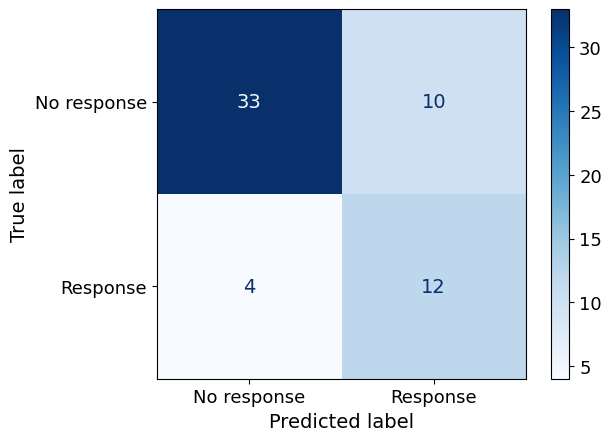

In [ ]:
baseline_model =LogisticRegression(C=0.1, solver= 'liblinear') # Alternative solver options
#baseline_model=AdaBoostClassifier(learning_rate= 1, n_estimators= 100) # Alternative solver options
#baseline_model=GradientBoostingClassifier( n_estimators= 100, criterion="friedman_mse") # Alternative solver options
#baseline_model=AdaBoostClassifier(learning_rate= 1, n_estimators= 100) # Alternative solver options
#baseline_model=LGBMClassifier(learning_rate= 0.2, n_estimators= 200, num_leaves=31)
#baseline_model=PassiveAggressiveClassifier(C= 0.1)
#baseline_model=Perceptron(alpha= 0.0001, penalty= 'l2')
baseline_model.fit(X_traine, y_traine)
y_pred =baseline_model.predict(X_test)
print(classification_report(y_test, y_pred))
cm =confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

              precision    recall  f1-score   support

           0       0.86      0.86      0.86        22
           1       0.67      0.67      0.67         9

    accuracy                           0.81        31
   macro avg       0.77      0.77      0.77        31
weighted avg       0.81      0.81      0.81        31



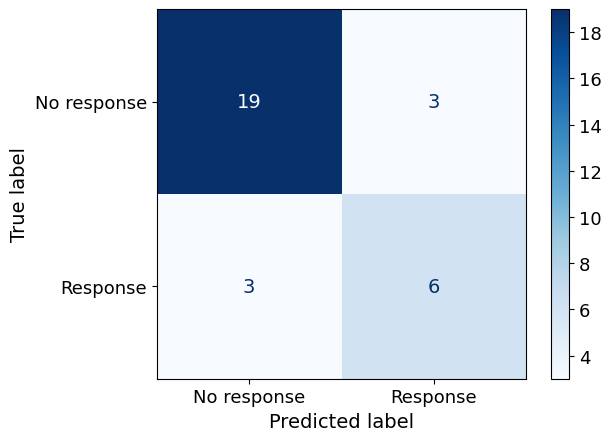

In [ ]:
baseline_model.fit(X_traine, y_traine)
y_pred =baseline_model.predict(X_val)
print(classification_report(y_val, y_pred))
cm =confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

AUC: 0.8283


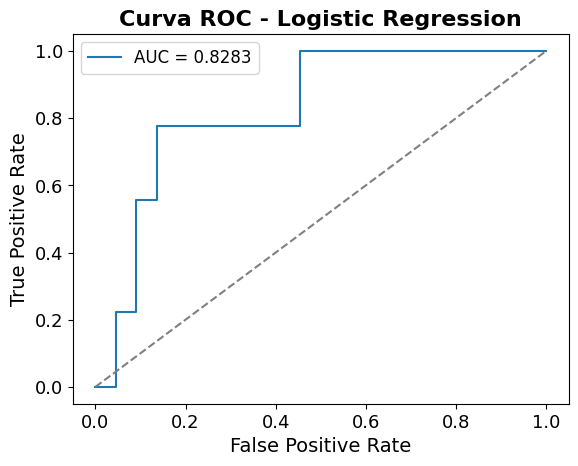

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
# Estimate probabilities for the positive class
y_probabilities = baseline_model.predict_proba(X_val)[:, 1]

# Compute AUC
auc = roc_auc_score(y_val, y_probabilities)
print(f"AUC: {auc:.4f}")

# Graficar curva ROC
fpr, tpr, _ = roc_curve(y_val, y_probabilities)
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")  # Línea de azar
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC - Logistic Regression")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
auc_scores = baseline_model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, auc_scores)
auc

np.float64(0.8677325581395349)

In [ ]:
# Estimate decision scores instead of probabilities
decision_scores = baseline_model.decision_function(X_test)

# Compute AUC
auc = roc_auc_score(y_test, decision_scores)
print(f"AUC: {auc:.4f}")

AUC: 0.8677


In [ ]:
from sklearn.metrics import roc_auc_score
auc_scores = baseline_model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, auc_scores)
auc

np.float64(0.8282828282828283)

In [ ]:
# Estimate decision scores instead of probabilities
decision_scores = baseline_model.decision_function(X_val)

# Compute AUC
auc = roc_auc_score(y_val, decision_scores)
print(f"AUC: {auc:.4f}")

AUC: 0.8283


✅ Mejor threshold por youden: t=0.3270 | score=0.5959
📈 AUC (threshold-free): 0.8677
              precision    recall  f1-score   support

 No response       0.92      0.77      0.84        43
    Response       0.57      0.81      0.67        16

    accuracy                           0.78        59
   macro avg       0.74      0.79      0.75        59
weighted avg       0.82      0.78      0.79        59



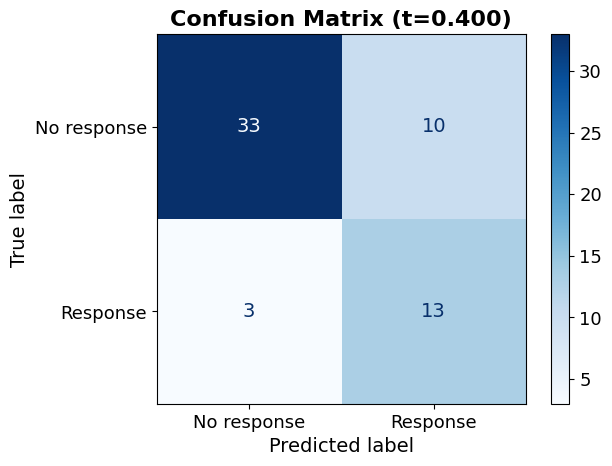

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, balanced_accuracy_score, f1_score
)

baseline_model.fit(X_traine, y_traine)

# 2) Estimate probabilities for the positive class
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# 3) Buscar mejor threshold (elige una métrica)
thresholds = np.linspace(0, 1, 1001)

best_t = 0.5
best_score = -np.inf

metric = "youden"  # "f1" o "bal_acc" o "youden"

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    if metric == "f1":
        score = f1_score(y_test, y_pred, zero_division=0)
    elif metric == "bal_acc":
        score = balanced_accuracy_score(y_test, y_pred)
    elif metric == "youden":
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        sens = tp / (tp + fn + 1e-12)
        spec = tn / (tn + fp + 1e-12)
        score = sens + spec - 1.0
    else:
        raise ValueError("metric debe ser: 'f1', 'bal_acc' o 'youden'")

    if score > best_score:
        best_score = score
        best_t = float(t)

print(f"✅ Mejor threshold por {metric}: t={best_t:.4f} | score={best_score:.4f}")

best_t =0.4

# 4) Final prediction using the optimal threshold
y_pred_best = (y_prob >= best_t).astype(int)

# Optional: AUC is threshold-independent
auc = roc_auc_score(y_test, y_prob)
print(f"📈 AUC (threshold-free): {auc:.4f}")

# 5) Reporte y matriz de confusión
print(classification_report(y_test, y_pred_best, target_names=["No response", "Response"]))

cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix (t={best_t:.3f})")
plt.show()


📈 AUC (threshold-free): 0.8283
              precision    recall  f1-score   support

 No response       0.90      0.82      0.86        22
    Response       0.64      0.78      0.70         9

    accuracy                           0.81        31
   macro avg       0.77      0.80      0.78        31
weighted avg       0.82      0.81      0.81        31



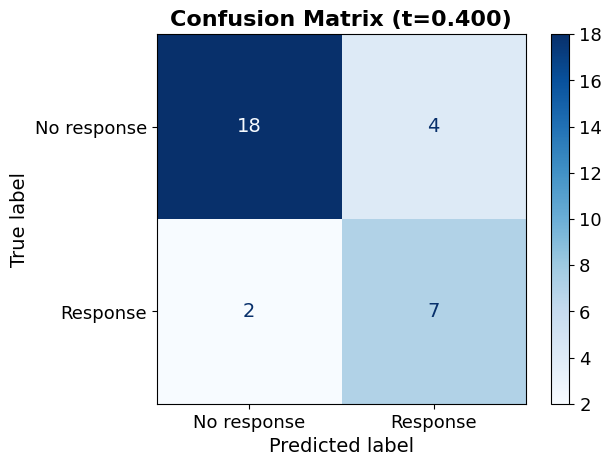

In [ ]:
baseline_model.fit(X_traine, y_traine)

# 2) Estimate probabilities for the positive class
y_prob = baseline_model.predict_proba(X_val)[:, 1]

# 4) Final prediction using the optimal threshold
y_pred_best = (y_prob >= best_t).astype(int)

# Optional: AUC is threshold-independent
auc = roc_auc_score(y_val, y_prob)
print(f"📈 AUC (threshold-free): {auc:.4f}")

# 5) Reporte y matriz de confusión
print(classification_report(y_val, y_pred_best, target_names=["No response", "Response"]))

cm = confusion_matrix(y_val, y_pred_best, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix (t={best_t:.3f})")
plt.show()


              precision    recall  f1-score   support

           0       0.94      0.86      0.90       445
           1       0.70      0.86      0.77       169

    accuracy                           0.86       614
   macro avg       0.82      0.86      0.83       614
weighted avg       0.87      0.86      0.86       614



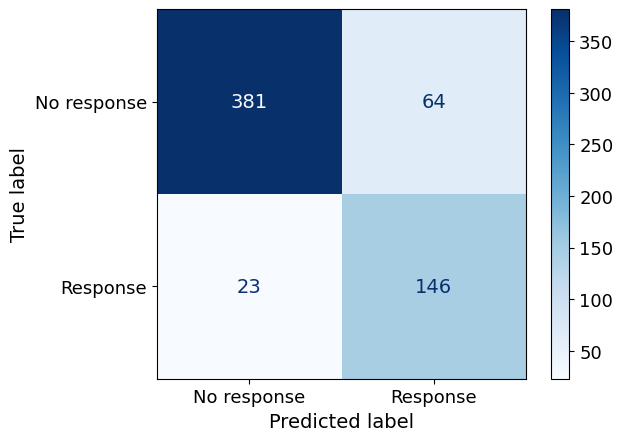

In [ ]:
# Gradient Boosting
#baseline_model = GradientBoostingClassifier(n_estimators=100, criterion= 'friedman_mse' )
#baseline_model = DecisionTreeClassifier (criterion = 'entropy', max_depth= 20 )
y_pred =baseline_model.predict(expression_matrix)
print(classification_report(y, y_pred))
cm =confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

In [ ]:
# Estimate decision scores instead of probabilities
decision_scores = baseline_model.decision_function(expression_matrix)

# Compute AUC
auc = roc_auc_score(y, decision_scores)
print(f"AUC: {auc:.4f}")

AUC: 0.9244


In [ ]:
# Replace slashes in clinical sample identifiers
clinical_metadata["run_accession"] = clinical_metadata["run_accession"].str.replace("/", ".")


## 9. SHAP model interpretation

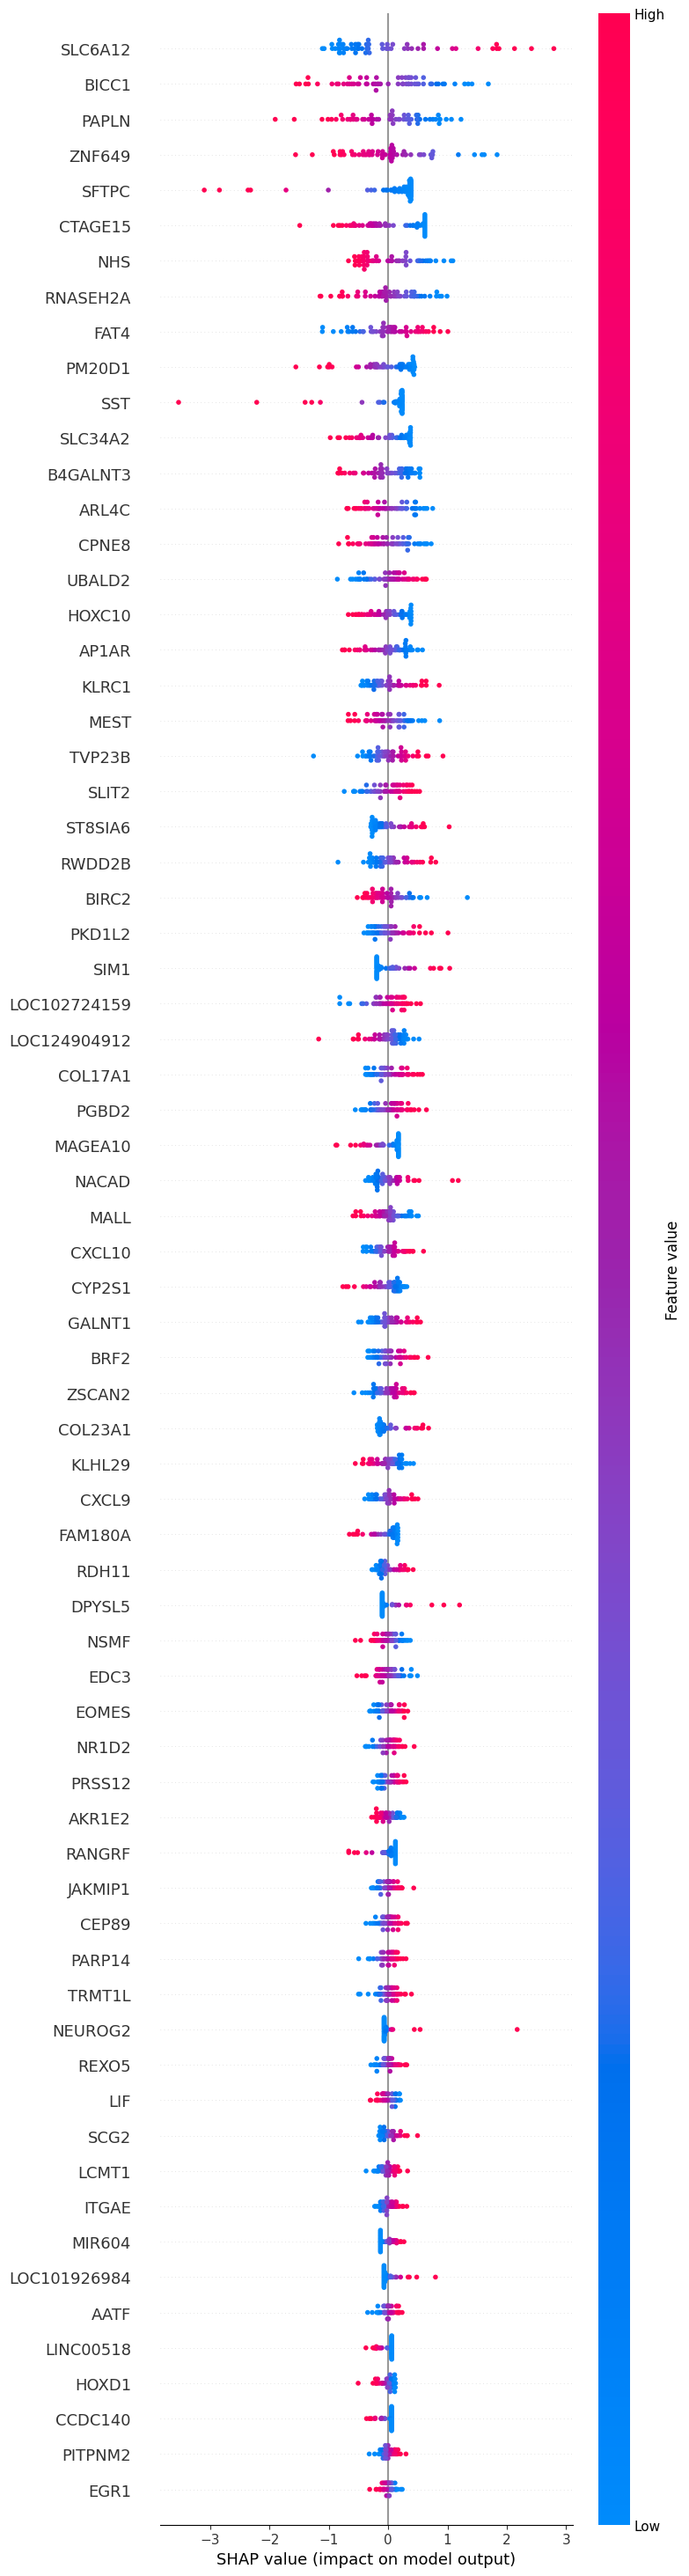

In [ ]:
# SHAP explainer for the linear model
#explainer = shap.Explainer(baseline_model)
explainer = shap.Explainer(baseline_model, X_test)
shap_values = explainer(X_test)

# Display SHAP values
shap.summary_plot(shap_values, X_test, max_display=70)

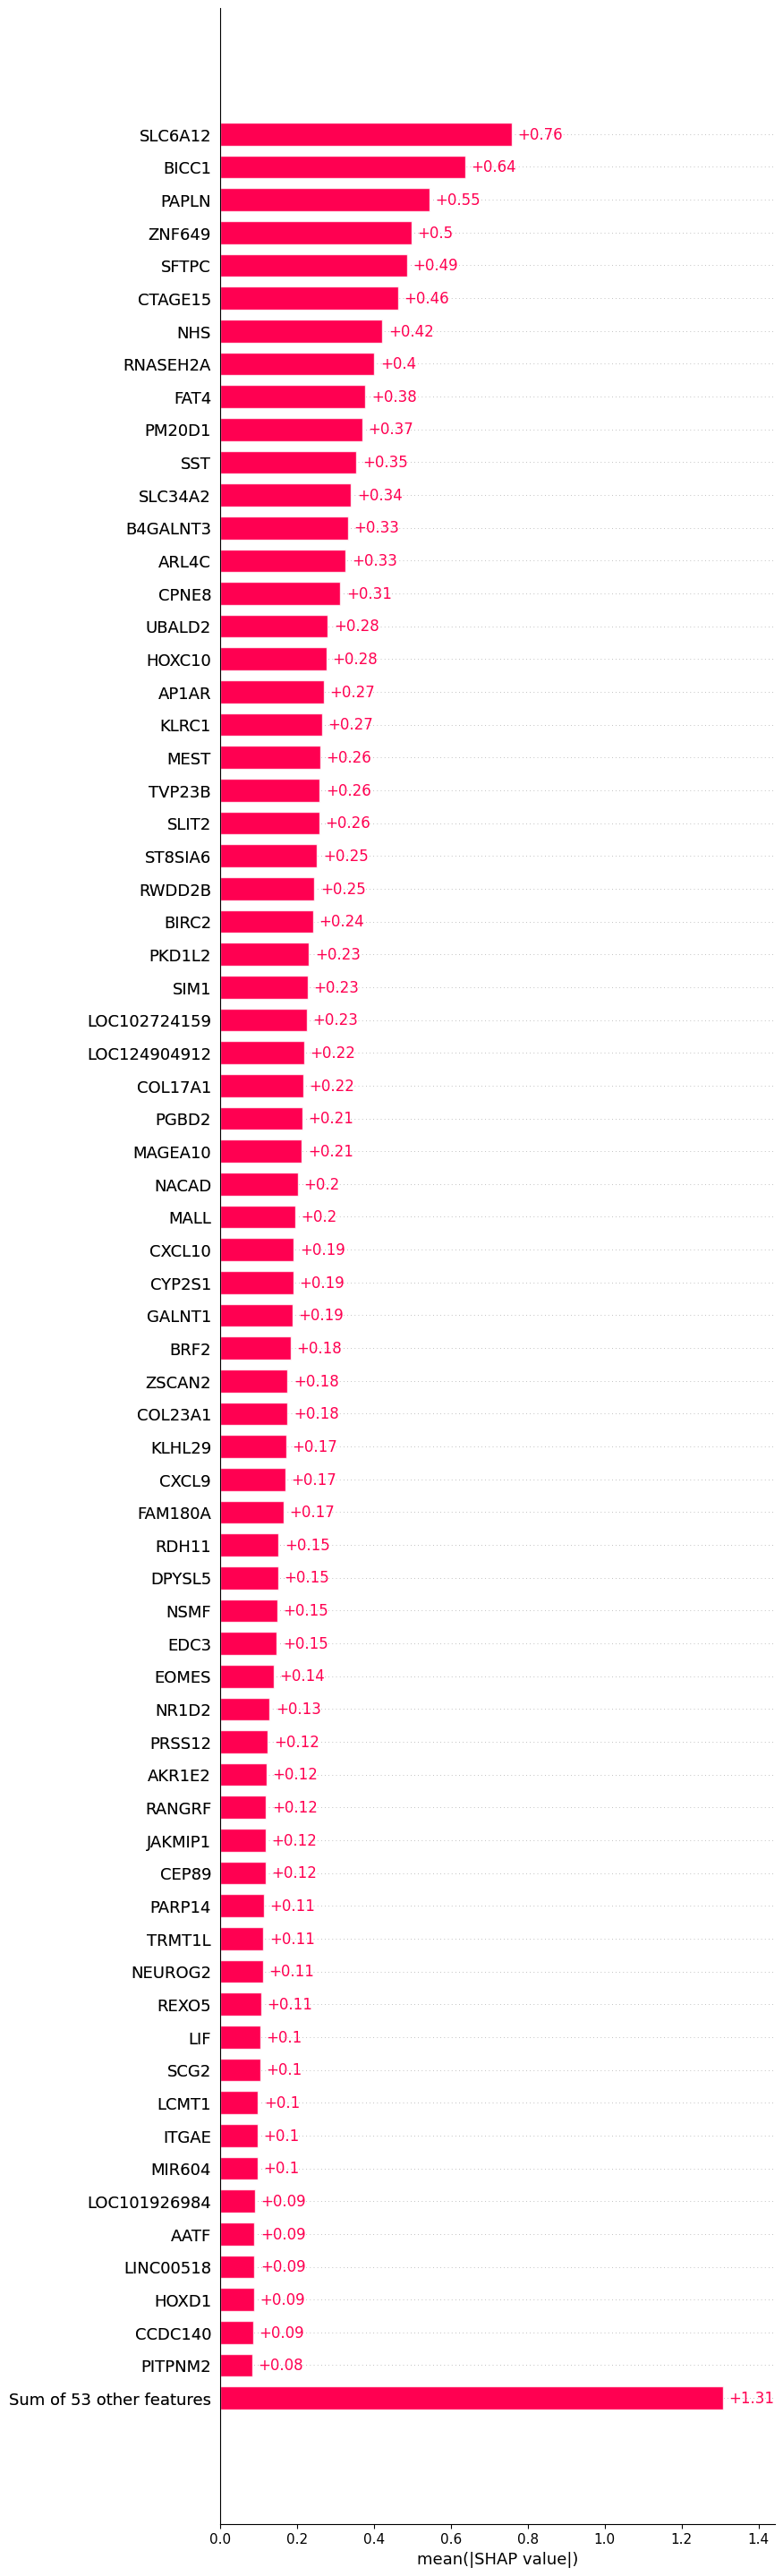

In [ ]:
shap.plots.bar(shap_values,  max_display=70)

In [ ]:
vals = np.abs(shap_values.values).mean(0)
feature_names = X_train.columns
feature_importance = pd.DataFrame(list(zip(feature_names, vals)),
                                 columns=['col_name','feature_importance_vals'])
feature_importance.sort_values(by=['feature_importance_vals'],
                              ascending=False, inplace=True)


# Definir el threshold mínimo de importancia (ajústalo según tu caso)
threshold = 0.00  # Cambia este valor según la distribución de importancia

# Filtrar solo las features con importancia mayor al threshold
shap_feature_ranking = feature_importance[feature_importance["feature_importance_vals"] > threshold].copy()

# Convertir en DataFrame y acumular en selected_genes
#shap_feature_ranking = pd.DataFrame(feature_importance)
#shap_feature_ranking = pd.DataFrame(feature_importance.iloc[0:60, :])  # Seleccionar las 60 más importantes

shap_feature_ranking.shape

(122, 2)

In [ ]:
shap_feature_ranking

,col_name,feature_importance_vals
59,SLC6A12,0.757777
90,BICC1,0.636831
84,PAPLN,0.545067
22,ZNF649,0.498397
112,SFTPC,0.485729
...,...,...
77,PAGE5,0.001195
38,LOC644277,0.000949
48,LOC105372521,0.000609
85,MIR542,0.000338


In [ ]:
#ordenar shap_feature_ranking de menor a mayor por la columna feature_importance_vals
shap_feature_ranking = shap_feature_ranking.sort_values(by="feature_importance_vals", ascending=False)
shap_feature_ranking


,col_name,feature_importance_vals
59,SLC6A12,0.757777
90,BICC1,0.636831
84,PAPLN,0.545067
22,ZNF649,0.498397
112,SFTPC,0.485729
...,...,...
77,PAGE5,0.001195
38,LOC644277,0.000949
48,LOC105372521,0.000609
85,MIR542,0.000338


In [ ]:
# Convert the selected features to a NumPy array
shap_feature_ranking["col_name"].to_numpy()

array(['SLC6A12', 'BICC1', 'PAPLN', 'ZNF649', 'SFTPC', 'CTAGE15', 'NHS',
       'RNASEH2A', 'FAT4', 'PM20D1', 'SST', 'SLC34A2', 'B4GALNT3',
       'ARL4C', 'CPNE8', 'UBALD2', 'HOXC10', 'AP1AR', 'KLRC1', 'MEST',
       'TVP23B', 'SLIT2', 'ST8SIA6', 'RWDD2B', 'BIRC2', 'PKD1L2', 'SIM1',
       'LOC102724159', 'LOC124904912', 'COL17A1', 'PGBD2', 'MAGEA10',
       'NACAD', 'MALL', 'CXCL10', 'CYP2S1', 'GALNT1', 'BRF2', 'ZSCAN2',
       'COL23A1', 'KLHL29', 'CXCL9', 'FAM180A', 'RDH11', 'DPYSL5', 'NSMF',
       'EDC3', 'EOMES', 'NR1D2', 'PRSS12', 'AKR1E2', 'RANGRF', 'JAKMIP1',
       'CEP89', 'PARP14', 'TRMT1L', 'NEUROG2', 'REXO5', 'LIF', 'SCG2',
       'LCMT1', 'ITGAE', 'MIR604', 'LOC101926984', 'AATF', 'LINC00518',
       'HOXD1', 'CCDC140', 'PITPNM2', 'EGR1', 'KASH5', 'MAP4K1', 'GRB10',
       'ANKRD27', 'LOC124903104', 'AMN1', 'SH2D5', 'RDM1', 'PAX3',
       'LOC105370964', 'CREB3L3', 'LINC00431', 'MYADML2', 'LRFN4', 'PERP',
       'LOC124900511', 'GPATCH1', 'QRSL1', 'PDIK1L', 'ANKRD18DP',

In [ ]:
shap_selected_features = shap_feature_ranking["col_name"].to_numpy()
shap_selected_features

array(['SLC6A12', 'BICC1', 'PAPLN', 'ZNF649', 'SFTPC', 'CTAGE15', 'NHS',
       'RNASEH2A', 'FAT4', 'PM20D1', 'SST', 'SLC34A2', 'B4GALNT3',
       'ARL4C', 'CPNE8', 'UBALD2', 'HOXC10', 'AP1AR', 'KLRC1', 'MEST',
       'TVP23B', 'SLIT2', 'ST8SIA6', 'RWDD2B', 'BIRC2', 'PKD1L2', 'SIM1',
       'LOC102724159', 'LOC124904912', 'COL17A1', 'PGBD2', 'MAGEA10',
       'NACAD', 'MALL', 'CXCL10', 'CYP2S1', 'GALNT1', 'BRF2', 'ZSCAN2',
       'COL23A1', 'KLHL29', 'CXCL9', 'FAM180A', 'RDH11', 'DPYSL5', 'NSMF',
       'EDC3', 'EOMES', 'NR1D2', 'PRSS12', 'AKR1E2', 'RANGRF', 'JAKMIP1',
       'CEP89', 'PARP14', 'TRMT1L', 'NEUROG2', 'REXO5', 'LIF', 'SCG2',
       'LCMT1', 'ITGAE', 'MIR604', 'LOC101926984', 'AATF', 'LINC00518',
       'HOXD1', 'CCDC140', 'PITPNM2', 'EGR1', 'KASH5', 'MAP4K1', 'GRB10',
       'ANKRD27', 'LOC124903104', 'AMN1', 'SH2D5', 'RDM1', 'PAX3',
       'LOC105370964', 'CREB3L3', 'LINC00431', 'MYADML2', 'LRFN4', 'PERP',
       'LOC124900511', 'GPATCH1', 'QRSL1', 'PDIK1L', 'ANKRD18DP',

## 10. Cross-validation

Resultado iteración: 0
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  46  47  48  49  50  51  52  53  54
  55  56  58  60  61  62  63  64  65  66  67  68  69  70  71  72  73  74
  75  76  77  78  79  80  81  82  83  84  85  86  87  88  90  91  92  93
  94  95  96  97  98  99 100 101 102 104 105 106 107 108 109 110 111 112
 113 114 115 117 119 121 123 125 126 127 128 129 130 132 134 135 136 137
 139 140 142 143 144 145 146 147 149 150 151 152 153 154 155 156 157 158
 159 160 161 162 163 164 165 167 168 169 170 171 172 173 174 175 178 179
 180 181 182 183 184 185 186 187 188 190 191 192 193 194 195 196 198 201
 202 203 204 205 206 207 208 209 212 213 214 215 216 217 218 219 220 222
 223 224 225 226 227 228 230 231 233 234 235 236 237 238 239 241 242 245
 247 248 249 251 252 253 254 255 256 257 258 259 260 261 262 263 264 265
 266 267 268 269 270 271 272


Final cross-validation results (mean ± SD):
Accuracy:     0.767 ± 0.045
AUC:          0.836 ± 0.059
F1-score:     0.725 ± 0.048
Precision:    0.719 ± 0.046
Recall:       0.683 ± 0.085
Specificity:  0.800 ± 0.052


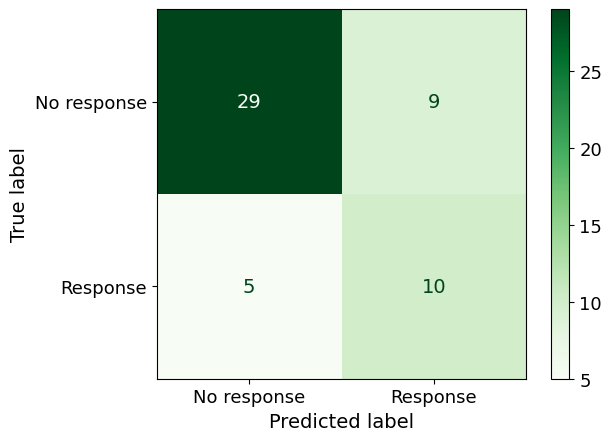

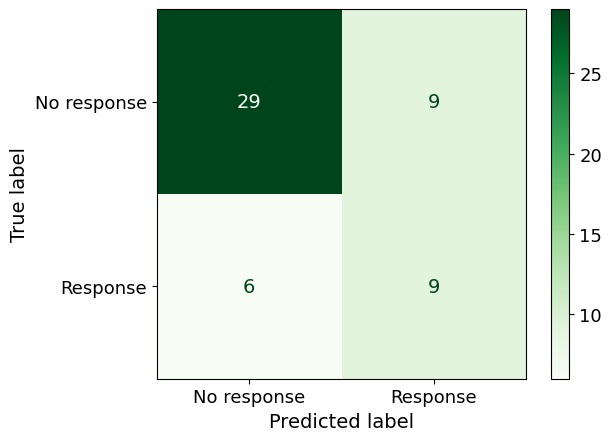

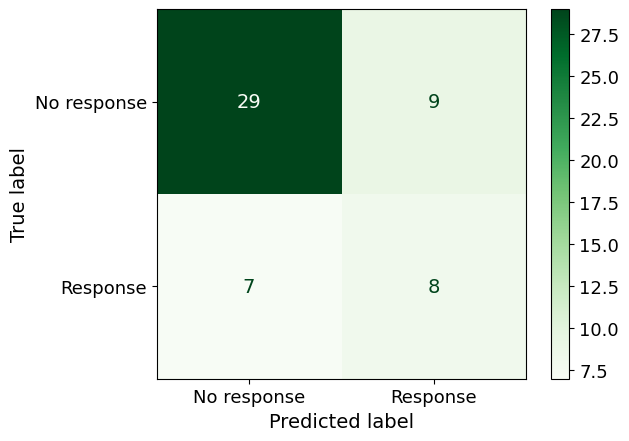

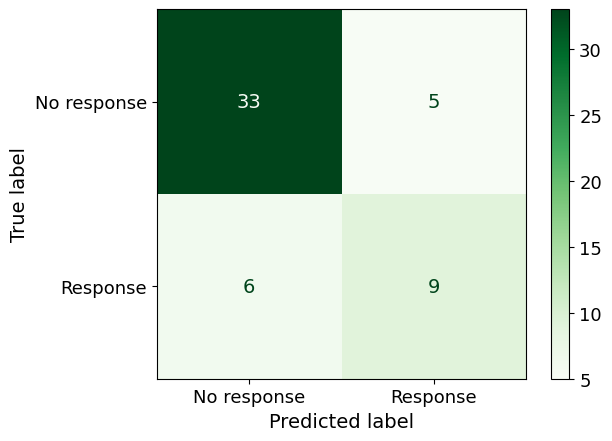

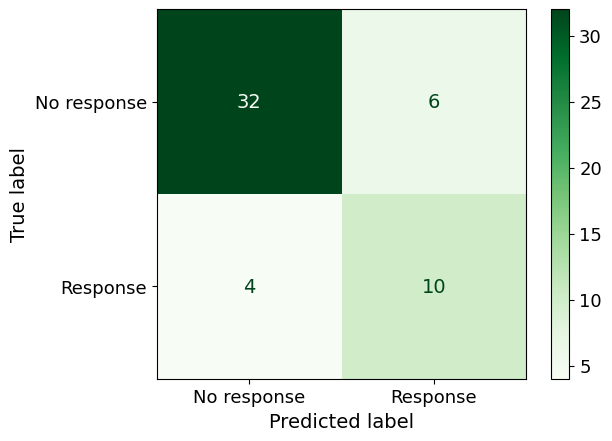

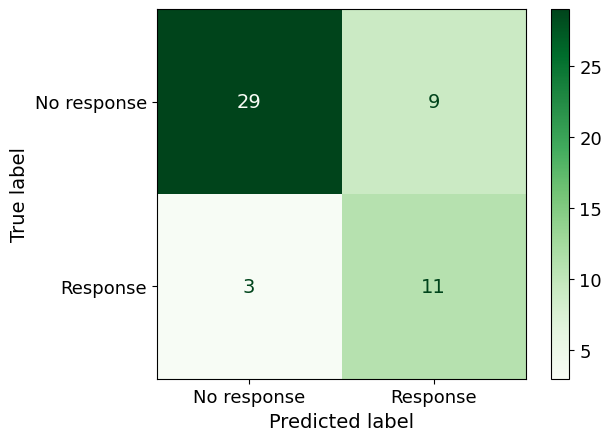

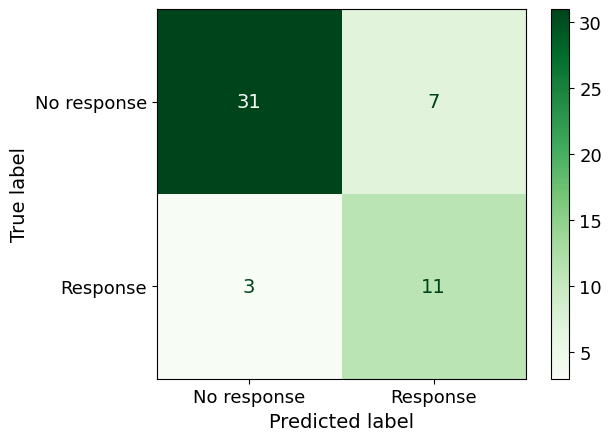

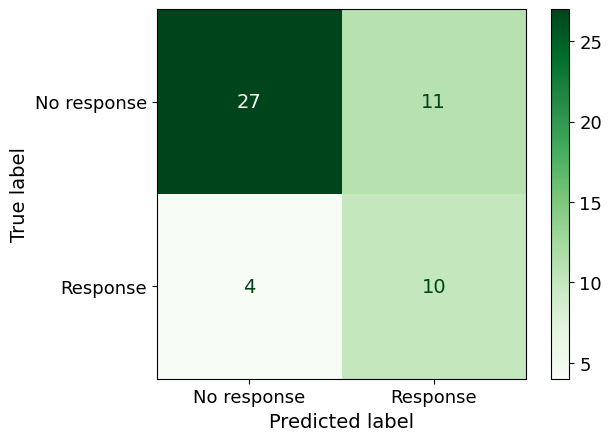

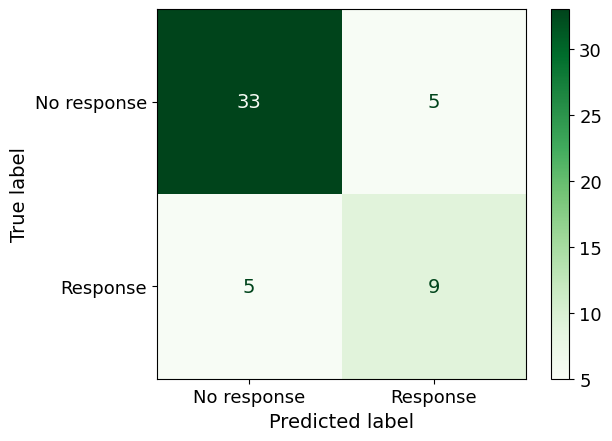

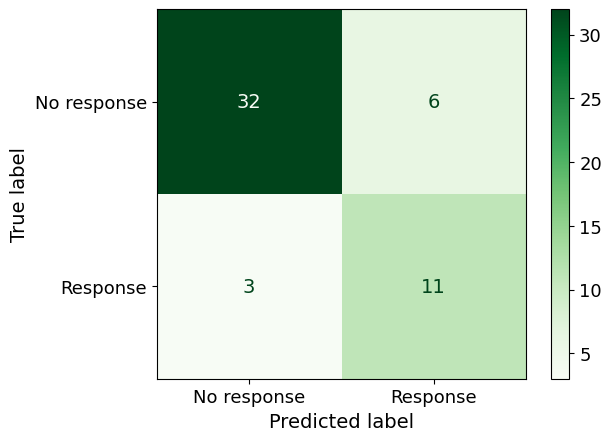

In [ ]:
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score
)

from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
import shap
import matplotlib.pyplot as plt

strtfdKFold = StratifiedKFold(n_splits=10, shuffle=True, random_state=5)
kfold = strtfdKFold.split(X_train, y_train)
scores = []
roc_score = []
f1_scores = []
precision_scores = []
recall_scores = []
specificity_scores = []
predicted_labels = []
observed_labels = []
i = 0
THRESHOLD = 0.5   # ejemplo

# Inicializar DataFrame para acumular shap_feature_ranking
selected_genes = pd.DataFrame()

for train_index, test_index in kfold:
    baseline_model = LogisticRegression(C= 0.1, solver= 'liblinear')
    X_train_cv, X_test_cv = X_train.values[train_index], X_train.values[test_index]
    y_train_cv, y_test_cv = y_train[train_index], y_train[test_index]

    # oversampling para el modelo
    X_train_cv, y_train_cv = SMOTE().fit_resample(X_train_cv, y_train_cv)

    baseline_model.fit(X_train_cv, y_train_cv)
    scores.append(baseline_model.score(X_test_cv, y_test_cv))

    auc_scores = baseline_model.predict_proba(X_test_cv)[:, 1]
    roc_score.append(roc_auc_score(y_test_cv, auc_scores))

    y_prob = baseline_model.predict_proba(X_test_cv)[:, 1]
    py = (y_prob >= THRESHOLD).astype(int)
    predicted_labels = list(itertools.chain(predicted_labels, py.flatten().tolist()))
    observed_labels = list(itertools.chain(observed_labels, y_test_cv.flatten().tolist()))

    # Compute métricas fold a fold

    f1_scores.append(f1_score(y_test_cv, py, average="macro"))
    precision_scores.append(precision_score(y_test_cv, py,average="macro"))
    recall_scores.append(recall_score(y_test_cv, py))

    # Compute especificidad (specificity)
    cm = confusion_matrix(y_test_cv, py)
    if cm.shape == (2, 2):  # Para evitar errores si solo hay una clase en el fold
        TN = cm[0, 0]
        FP = cm[0, 1]
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
        specificity_scores.append(specificity)
    else:
        specificity_scores.append(np.nan)

    print('Resultado iteración:', i)
    print(train_index)
    print(classification_report(y_test_cv, py))
    cm_val = confusion_matrix(y_test_cv, py)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=["No response", "Response"])
    disp.plot(cmap=plt.cm.Greens)
    i += 1

# Cálculo de promedios y desviaciones estándar
accuracy_test = np.mean(scores)
accuracy_desv = np.std(scores)

auc_test = np.mean(roc_score)
auc_test_desv = np.std(roc_score)

f1_test = np.mean(f1_scores)
f1_test_desv = np.std(f1_scores)

precision_test = np.mean(precision_scores)
precision_test_desv = np.std(precision_scores)

recall_test = np.mean(recall_scores)
recall_test_desv = np.std(recall_scores)

specificity_test = np.nanmean(specificity_scores)
specificity_test_desv = np.nanstd(specificity_scores)

print("\nFinal cross-validation results (mean ± SD):")
print(f"Accuracy:     {accuracy_test:.3f} ± {accuracy_desv:.3f}")
print(f"AUC:          {auc_test:.3f} ± {auc_test_desv:.3f}")
print(f"F1-score:     {f1_test:.3f} ± {f1_test_desv:.3f}")
print(f"Precision:    {precision_test:.3f} ± {precision_test_desv:.3f}")
print(f"Recall:       {recall_test:.3f} ± {recall_test_desv:.3f}")
print(f"Specificity:  {specificity_test:.3f} ± {specificity_test_desv:.3f}")


In [ ]:
print("\nFinal cross-validation results (mean ± SD):")
print(f"Accuracy:     {accuracy_test:.3f} ± {accuracy_desv:.3f}")
print(f"AUC:          {auc_test:.3f} ± {auc_test_desv:.3f}")
print(f"F1-score:     {f1_test:.3f} ± {f1_test_desv:.3f}")
print(f"Precision:    {precision_test:.3f} ± {precision_test_desv:.3f}")
print(f"Recall:       {recall_test:.3f} ± {recall_test_desv:.3f}")
print(f"Specificity:  {specificity_test:.3f} ± {specificity_test_desv:.3f}")


Final cross-validation results (mean ± SD):
Accuracy:     0.767 ± 0.045
AUC:          0.836 ± 0.059
F1-score:     0.725 ± 0.048
Precision:    0.719 ± 0.046
Recall:       0.683 ± 0.085
Specificity:  0.800 ± 0.052


In [ ]:
print(classification_report(observed_labels, predicted_labels))

              precision    recall  f1-score   support

           0       0.87      0.80      0.83       380
           1       0.56      0.68      0.62       144

    accuracy                           0.77       524
   macro avg       0.72      0.74      0.72       524
weighted avg       0.78      0.77      0.77       524



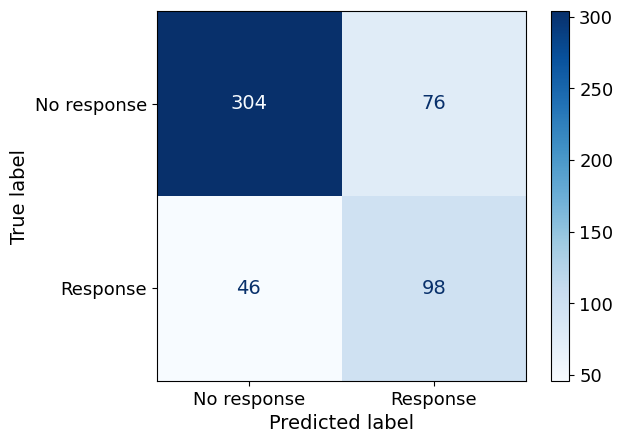

In [ ]:
cm =[confusion_matrix(observed_labels,predicted_labels)]
disp = ConfusionMatrixDisplay(confusion_matrix=cm[0], display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

## 11. Final 51-gene model

In [1]:
X_traine2 = X_traine[shap_selected_features]
X_train2 = X_train[shap_selected_features]
X_test2 = X_test[shap_selected_features]
X_val2 = X_val[shap_selected_features]
X_cruz2 = X_cruz[shap_selected_features]
X_traine2

NameError: name 'X_traine' is not defined

In [ ]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.15)  # adjust the threshold according to your dataset
filtered_feature_matrix = selector.fit_transform(X_train2)
# Retrieve the retained columns
selected_columns = X_train2.columns[selector.get_support()]
filtered_feature_matrix = pd.DataFrame(filtered_feature_matrix, columns=selected_columns)


In [ ]:
low_variance_features = X_train2.columns[~selector.get_support()]
print("Features removed by low variance:", list(low_variance_features))

In [2]:
variance_selected_features =filtered_feature_matrix.columns.to_numpy()
variance_selected_features

NameError: name 'filtered_feature_matrix' is not defined

In [3]:
X_traine2 = X_traine[variance_selected_features]
X_train2 = X_train[variance_selected_features]
X_test2 = X_test[variance_selected_features]
X_val2 = X_val[variance_selected_features]
X_cruz2 = X_cruz[variance_selected_features]
X_traine2

NameError: name 'X_traine' is not defined

In [ ]:

# X: feature matrix
# y: binary target vector

candidate_features = list(X_traine2.columns)

# Function to compute mean AUC using cross-validation
def mean_auc(X_subset, y, cv_folds=5):
    model = LogisticRegression(C= 0.1, solver= 'liblinear')
    aucs = cross_val_score(model, X_subset, y, cv=cv_folds, scoring='roc_auc')
    return aucs.mean()

# AUC inicial con todas las candidate_features
best_auc = mean_auc(X_traine2[candidate_features], y_traine)

# Save figure el registro del proceso
registro = []

# Iteración secuencial
i = 0
while i < len(candidate_features):
    var_actual = candidate_features[i]
    vars_sin_actual = candidate_features[:i] + candidate_features[i+1:]

    auc_tmp = mean_auc(X_traine2[vars_sin_actual], y_traine)

    # Decisión: feature_to_remove si mejora o se mantiene el AUC
    if auc_tmp >= best_auc:
        eliminado = True
        candidate_features = vars_sin_actual
        best_auc = auc_tmp
        # no avanzar i, porque los índices cambiaron
    else:
        eliminado = False
        i += 1  # pasar a la siguiente variable

    registro.append({
        'variable': var_actual,
        'auc_nuevo': auc_tmp,
        'eliminado': eliminado,
        'auc_base': best_auc
    })

# Convertir results a DataFrame
feature_elimination_results = pd.DataFrame(registro)



In [4]:
feature_elimination_results

NameError: name 'feature_elimination_results' is not defined

In [5]:
len(candidate_features)

NameError: name 'candidate_features' is not defined

In [6]:
X_traine2 = X_traine[candidate_features]
X_train2 = X_train[candidate_features]
X_test2 = X_test[candidate_features]
X_val2 = X_val[candidate_features]
X_cruz2 = X_cruz[candidate_features]
X_traine2

NameError: name 'X_traine' is not defined

In [ ]:

# X: feature matrix
# y: binary target vector

candidate_features = list(X_traine2.columns)

# Function to compute mean AUC using cross-validation
def mean_auc(X_subset, y, cv_folds=5):
    model = LogisticRegression(C= 0.1, solver= 'liblinear')
    aucs = cross_val_score(model, X_subset, y, cv=cv_folds, scoring='roc_auc')
    return aucs.mean()

# AUC inicial con todas las candidate_features
best_auc = mean_auc(X_traine2[candidate_features], y_traine)

# Save figure el registro del proceso
registro = []

# Iteración secuencial
i = 0
while i < len(candidate_features):
    var_actual = candidate_features[i]
    vars_sin_actual = candidate_features[:i] + candidate_features[i+1:]

    auc_tmp = mean_auc(X_traine2[vars_sin_actual], y_traine)

    # Decisión: feature_to_remove si mejora o se mantiene el AUC
    if auc_tmp >= best_auc:
        eliminado = True
        candidate_features = vars_sin_actual
        best_auc = auc_tmp
        # no avanzar i, porque los índices cambiaron
    else:
        eliminado = False
        i += 1  # pasar a la siguiente variable

    registro.append({
        'variable': var_actual,
        'auc_nuevo': auc_tmp,
        'eliminado': eliminado,
        'auc_base': best_auc
    })

# Convertir results a DataFrame
feature_elimination_results = pd.DataFrame(registro)



In [ ]:
len(candidate_features)

In [7]:
X_traine2 = X_traine[candidate_features]
X_train2 = X_train[candidate_features]
X_test2 = X_test[candidate_features]
X_val2 = X_val[candidate_features]
X_cruz2 = X_cruz[candidate_features]
X_traine2

NameError: name 'X_traine' is not defined

In [ ]:

# X: feature matrix
# y: binary target vector

candidate_features = list(X_traine2.columns)

# Function to compute mean AUC using cross-validation
def mean_auc(X_subset, y, cv_folds=5):
    model = LogisticRegression(C= 0.1, solver= 'liblinear')
    aucs = cross_val_score(model, X_subset, y, cv=cv_folds, scoring='roc_auc')
    return aucs.mean()

# AUC inicial con todas las candidate_features
best_auc = mean_auc(X_traine2[candidate_features], y_traine)

# Save figure el registro del proceso
registro = []

# Iteración secuencial
i = 0
while i < len(candidate_features):
    var_actual = candidate_features[i]
    vars_sin_actual = candidate_features[:i] + candidate_features[i+1:]

    auc_tmp = mean_auc(X_traine2[vars_sin_actual], y_traine)

    # Decisión: feature_to_remove si mejora o se mantiene el AUC
    if auc_tmp >= best_auc:
        eliminado = True
        candidate_features = vars_sin_actual
        best_auc = auc_tmp
        # no avanzar i, porque los índices cambiaron
    else:
        eliminado = False
        i += 1  # pasar a la siguiente variable

    registro.append({
        'variable': var_actual,
        'auc_nuevo': auc_tmp,
        'eliminado': eliminado,
        'auc_base': best_auc
    })

# Convertir results a DataFrame
feature_elimination_results = pd.DataFrame(registro)



In [ ]:
len(candidate_features)

In [8]:
X_traine2 = X_traine[candidate_features]
X_train2 = X_train[candidate_features]
X_test2 = X_test[candidate_features]
X_val2 = X_val[candidate_features]
X_cruz2 = X_cruz[candidate_features]
X_traine2

NameError: name 'X_traine' is not defined

In [ ]:

# X: feature matrix
# y: binary target vector

candidate_features = list(X_traine2.columns)

# Function to compute mean AUC using cross-validation
def mean_auc(X_subset, y, cv_folds=5):
    model = LogisticRegression(C= 0.1, solver= 'liblinear')
    aucs = cross_val_score(model, X_subset, y, cv=cv_folds, scoring='roc_auc')
    return aucs.mean()

# AUC inicial con todas las candidate_features
best_auc = mean_auc(X_traine2[candidate_features], y_traine)

# Save figure el registro del proceso
registro = []

# Iteración secuencial
i = 0
while i < len(candidate_features):
    var_actual = candidate_features[i]
    vars_sin_actual = candidate_features[:i] + candidate_features[i+1:]

    auc_tmp = mean_auc(X_traine2[vars_sin_actual], y_traine)

    # Decisión: feature_to_remove si mejora o se mantiene el AUC
    if auc_tmp >= best_auc:
        eliminado = True
        candidate_features = vars_sin_actual
        best_auc = auc_tmp
        # no avanzar i, porque los índices cambiaron
    else:
        eliminado = False
        i += 1  # pasar a la siguiente variable

    registro.append({
        'variable': var_actual,
        'auc_nuevo': auc_tmp,
        'eliminado': eliminado,
        'auc_base': best_auc
    })

# Convertir results a DataFrame
feature_elimination_results = pd.DataFrame(registro)



In [ ]:
len(candidate_features)

In [9]:
X_traine2 = X_traine[candidate_features]
X_train2 = X_train[candidate_features]
X_test2 = X_test[candidate_features]
X_val2 = X_val[candidate_features]
X_cruz2 = X_cruz[candidate_features]
X_traine2

NameError: name 'X_traine' is not defined

In [10]:
candidate_features

NameError: name 'candidate_features' is not defined

## 12. Final model training and evaluation

              precision    recall  f1-score   support

           0       0.87      0.79      0.83        43
           1       0.55      0.69      0.61        16

    accuracy                           0.76        59
   macro avg       0.71      0.74      0.72        59
weighted avg       0.78      0.76      0.77        59



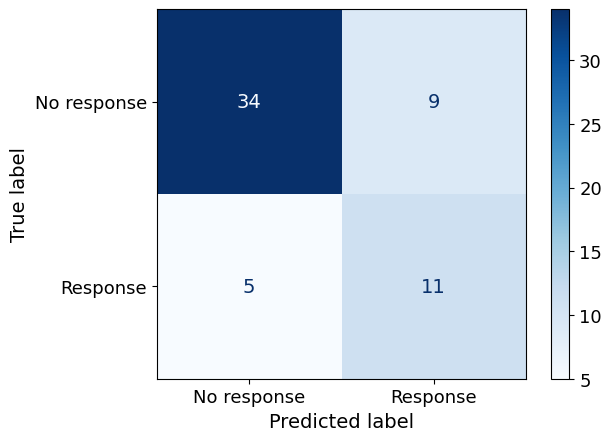

In [ ]:
final_model =LogisticRegression(C= 0.1, solver= 'liblinear')
#final_model=GradientBoostingClassifier( n_estimators= 100, criterion="friedman_mse")
final_model.fit(X_traine2, y_traine)
y_pred =final_model.predict(X_test2)
print(classification_report(y_test, y_pred))
cm =confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

AUC: 0.8416


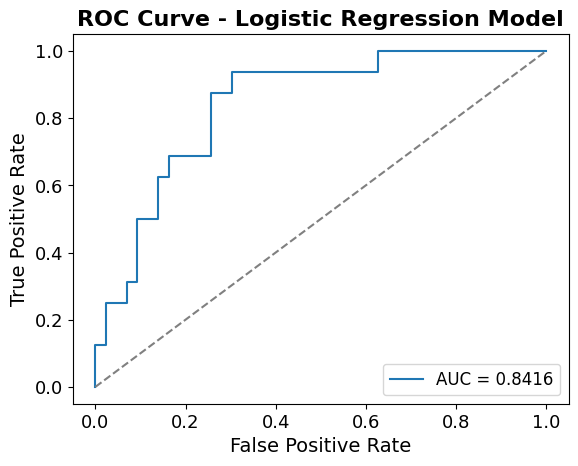

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
# Estimate probabilities for the positive class
y_probabilities = final_model.predict_proba(X_test2)[:, 1]

# Compute AUC
auc = roc_auc_score(y_test, y_probabilities)
print(f"AUC: {auc:.4f}")

# Graficar curva ROC
fpr, tpr, _ = roc_curve(y_test, y_probabilities)
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")  # Línea de azar
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression Model")
plt.legend()
plt.savefig("roc_lr.png", dpi=300, bbox_inches='tight')
plt.show()

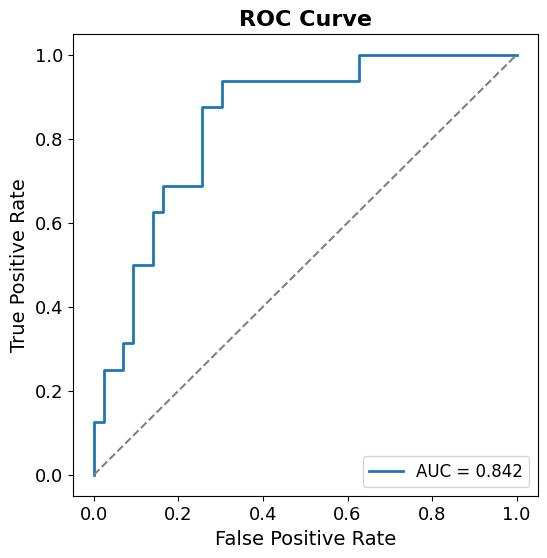

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Predicted probabilities
y_probabilities = final_model.predict_proba(X_test2)[:, 1]

# AUC
auc = roc_auc_score(y_test, y_probabilities)

# ROC
fpr, tpr, _ = roc_curve(y_test, y_probabilities)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], '--', color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

# GUARDAR ANTES DE SHOW
plt.savefig("roc_lr.png", dpi=600, bbox_inches="tight")
plt.savefig("roc_lr.pdf", bbox_inches="tight")

plt.show()
plt.close()

In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix, accuracy_score

# Class predictions
y_pred_test = final_model.predict(X_test2)

# Métricas individuales
accuracy = accuracy_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

cm = confusion_matrix(y_test, y_pred_test)
if cm.shape == (2, 2):
    TN = cm[0, 0]
    FP = cm[0, 1]
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
else:
    specificity = float('nan')

print(f"Accuracy:     {accuracy:.2f}")
print(f"Recall:       {recall:.2f}")
print(f"Specificity:  {specificity:.2f}")
print(f"F1-score:     {f1:.2f}")
print(f"Precision:    {precision:.2f}")

Accuracy:     0.76
Recall:       0.69
Specificity:  0.79
F1-score:     0.61
Precision:    0.55


              precision    recall  f1-score   support

           0       0.90      0.82      0.86        22
           1       0.64      0.78      0.70         9

    accuracy                           0.81        31
   macro avg       0.77      0.80      0.78        31
weighted avg       0.82      0.81      0.81        31



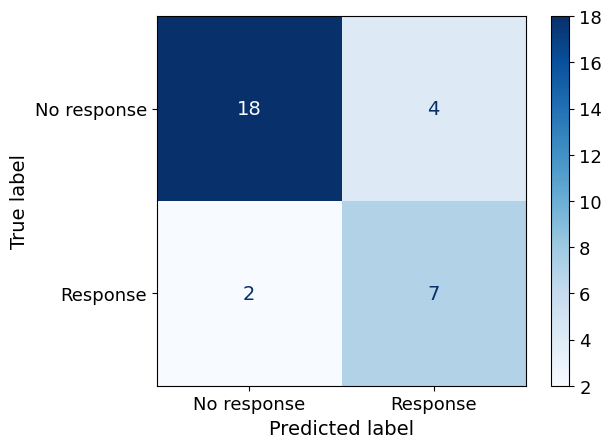

In [ ]:
y_pred =final_model.predict(X_val2)
print(classification_report(y_val, y_pred))
cm =confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No response", "Response"])
disp.plot(cmap=plt.cm.Blues)

AUC: 0.8030


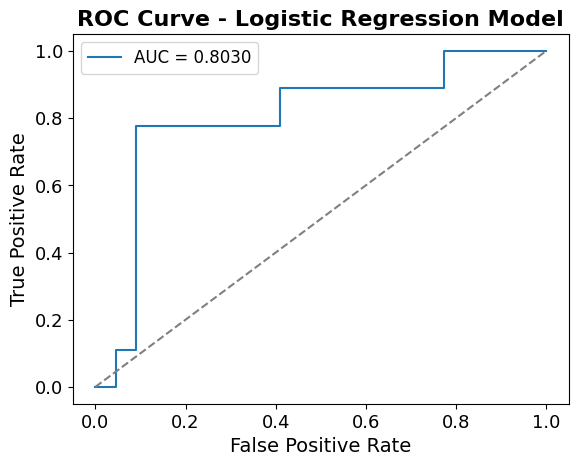

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
# Estimate probabilities for the positive class
y_probabilities = final_model.predict_proba(X_val2)[:, 1]

# Compute AUC
auc = roc_auc_score(y_val, y_probabilities)
print(f"AUC: {auc:.4f}")

# Graficar curva ROC
fpr, tpr, _ = roc_curve(y_val, y_probabilities)
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")  # Línea de azar
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression Model")
plt.legend()
plt.savefig("roc_lrval.png", dpi=300, bbox_inches='tight')
plt.show()

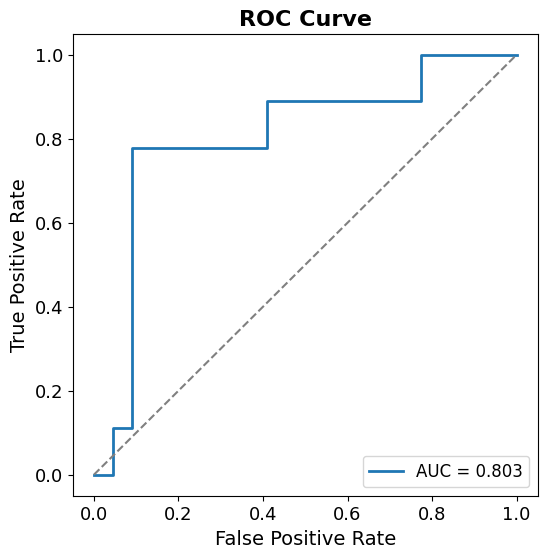

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Predicted probabilities
y_probabilities = final_model.predict_proba(X_val2)[:, 1]

# AUC
auc = roc_auc_score(y_val, y_probabilities)

# ROC
fpr, tpr, _ = roc_curve(y_val, y_probabilities)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], '--', color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

# GUARDAR ANTES DE SHOW
plt.savefig("roc_lr.png", dpi=600, bbox_inches="tight")
plt.savefig("roc_lr.pdf", bbox_inches="tight")

plt.show()
plt.close()

In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix, accuracy_score

# Class predictions
y_pred_test = final_model.predict(X_val2)

# Métricas individuales
accuracy = accuracy_score(y_val, y_pred_test)
recall = recall_score(y_val, y_pred_test)
precision = precision_score(y_val, y_pred_test)
f1 = f1_score(y_val, y_pred_test)

cm = confusion_matrix(y_val, y_pred_test)
if cm.shape == (2, 2):
    TN = cm[0, 0]
    FP = cm[0, 1]
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
else:
    specificity = float('nan')

print(f"Accuracy:     {accuracy:.2f}")
print(f"Recall:       {recall:.2f}")
print(f"Specificity:  {specificity:.2f}")
print(f"F1-score:     {f1:.2f}")
print(f"Precision:    {precision:.2f}")

Accuracy:     0.81
Recall:       0.78
Specificity:  0.82
F1-score:     0.70
Precision:    0.64


In [ ]:
from sklearn.metrics import roc_auc_score
auc_scores = final_model.predict_proba(X_test2)[:, 1]
auc = roc_auc_score(y_test, auc_scores)
auc

np.float64(0.8415697674418605)

In [ ]:
from sklearn.metrics import roc_auc_score
auc_scores = final_model.predict_proba(X_val2)[:, 1]
auc = roc_auc_score(y_val, auc_scores)
auc

np.float64(0.8030303030303031)

In [ ]:

import numpy as np
import pandas as pd

# Extraer parámetros del modelo entrenado
genes = list(X_traine2.columns)
coef = final_model.coef_[0]
intercept = final_model.intercept_[0]

assert len(genes) == 51
assert len(coef) == 51

tabla_s1 = pd.DataFrame({
    "Feature order": np.arange(1, 52),
    "Gene identifier": genes,
    "Coefficient (beta)": coef,
    "Odds ratio (exp beta)": np.exp(coef)
})

display(tabla_s1)
print("Intercept:", intercept)
print("Threshold: 0.50")

tabla_s1.to_excel(
    "Supplementary_Table_S1_parameters.xlsx",
    index=False
)


,Feature order,Gene identifier,Coefficient (beta),Odds ratio (exp beta)
0,1,SLC6A12,0.543572,1.722148
1,2,BICC1,-0.417797,0.658496
2,3,PAPLN,-0.593031,0.552650
3,4,ZNF649,-0.548100,0.578047
4,5,SFTPC,-0.433818,0.648030
5,6,CTAGE15,-0.475573,0.621529
6,7,NHS,-0.187488,0.829039
7,8,RNASEH2A,-0.726789,0.483459
8,9,FAT4,0.380000,1.462285
9,10,PM20D1,-0.187033,0.829417


Intercept: -0.031026254060088486
Threshold: 0.50


In [ ]:
import joblib

model_output_path = '/content/drive/MyDrive/Colab Notebooks/AUNA/modelo_logistico1.pkl'
joblib.dump(final_model, model_output_path)

['/content/drive/MyDrive/Colab Notebooks/AUNA/modelo_logistico1.pkl']

In [ ]:
final_gene_list =X_traine2.columns.to_numpy()
final_gene_list

array(['SLC6A12', 'BICC1', 'PAPLN', 'ZNF649', 'SFTPC', 'CTAGE15', 'NHS',
       'RNASEH2A', 'FAT4', 'PM20D1', 'SST', 'B4GALNT3', 'CPNE8', 'UBALD2',
       'AP1AR', 'KLRC1', 'MEST', 'TVP23B', 'SLIT2', 'ST8SIA6', 'RWDD2B',
       'BIRC2', 'PKD1L2', 'LOC102724159', 'LOC124904912', 'COL17A1',
       'PGBD2', 'NACAD', 'MALL', 'CYP2S1', 'GALNT1', 'BRF2', 'ZSCAN2',
       'CXCL9', 'FAM180A', 'DPYSL5', 'NSMF', 'EDC3', 'EOMES', 'JAKMIP1',
       'CEP89', 'PARP14', 'LIF', 'LCMT1', 'ITGAE', 'MIR604', 'AATF',
       'HOXD1', 'CCDC140', 'AMN1', 'MYADML2'], dtype=object)

In [ ]:
df3 =expression_matrix[final_gene_list]
df3

Geneid,SLC6A12,BICC1,PAPLN,ZNF649,SFTPC,CTAGE15,NHS,RNASEH2A,FAT4,PM20D1,...,PARP14,LIF,LCMT1,ITGAE,MIR604,AATF,HOXD1,CCDC140,AMN1,MYADML2
gned.SRR7344546,1.159262,6.216224,4.223360,4.586408,0.000000,0.000000,3.452818,3.951613,4.191251,0.114006,...,9.138552,5.229188,4.630180,2.937445,0.114006,6.206618,0.410249,1.403037,3.012869,0.114006
gned.SRR7344548,0.719544,6.183625,4.439168,3.561751,0.000000,0.244595,3.606205,4.227817,5.485046,0.127475,...,7.530106,0.872964,3.781198,4.169760,0.244595,5.692558,0.719544,0.719544,3.146054,0.352917
gned.SRR7344554,0.824611,4.441096,2.279557,4.831316,0.366416,0.132751,4.714363,4.174698,2.416083,0.973664,...,8.156962,1.924132,3.895209,3.462543,0.000000,5.689317,1.596470,1.641735,3.524272,0.000000
gned.SRR7344564,1.239781,5.126851,6.391053,2.355606,0.614820,0.000000,3.359761,4.922426,4.684176,0.413707,...,6.369194,2.176420,4.678574,4.844521,0.047134,5.488777,1.761774,0.676075,2.410708,0.179946
gned.SRR7344565,0.987645,4.451088,5.438073,1.801686,0.604435,0.194781,2.368227,5.450526,2.685965,0.157872,...,5.772341,1.825417,4.901169,5.310405,0.041117,5.546458,2.073487,0.966457,2.400184,0.230770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERR2208953,0.757088,4.416653,2.447348,4.124026,0.860402,0.000000,4.167486,5.130654,5.298729,4.019082,...,8.674378,4.116219,5.201235,3.349161,0.979937,6.093442,1.025109,0.493414,3.815583,0.358738
ERR2208954,2.150105,4.755221,3.610178,3.976076,0.366205,1.495918,5.595750,5.435448,5.485622,3.319993,...,10.696285,3.522204,5.166159,5.579277,0.784416,6.271036,0.230664,0.000000,2.821327,0.000000
ERR2208967,1.527682,4.930917,3.372440,4.215425,1.386364,0.729125,4.426680,5.118880,5.202069,2.881093,...,8.299709,3.108117,5.529737,3.393112,1.053894,6.483518,0.592800,0.237997,4.462331,0.042494
ERR2208973,1.092715,3.771902,3.064000,3.572210,0.677794,1.321483,4.671712,5.173206,5.694153,1.925453,...,9.281884,3.643174,5.006776,3.349828,1.115078,6.931183,0.450462,0.047282,4.109219,0.000000


[Umbrales en TEST]
thr_0.5 = 0.500
thr_youden = 0.350471 | J=0.635 | sens=0.938 | spec=0.698
thr_max_recall_spec0.75 = 0.641492 | sens=0.688 | spec=0.837


,threshold_name,thr,accuracy,sensibilidad,especificidad,TN,FP,FN,TP
0,thr_0.5,0.500000,0.762712,0.6875,0.790698,34,9,5,11
1,thr_youden,0.350471,0.762712,0.9375,0.697674,30,13,1,15
2,thr_max_recall_spec0.75,0.641492,0.796610,0.6875,0.837209,36,7,5,11


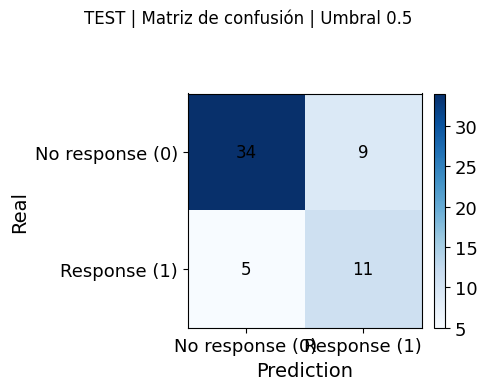

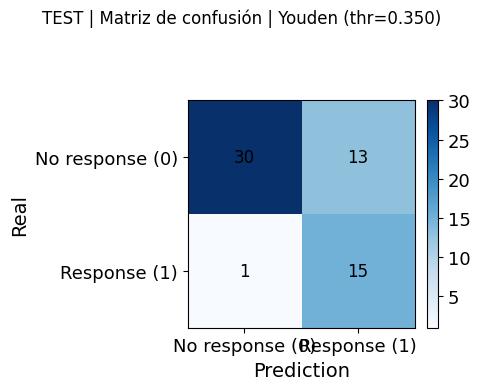

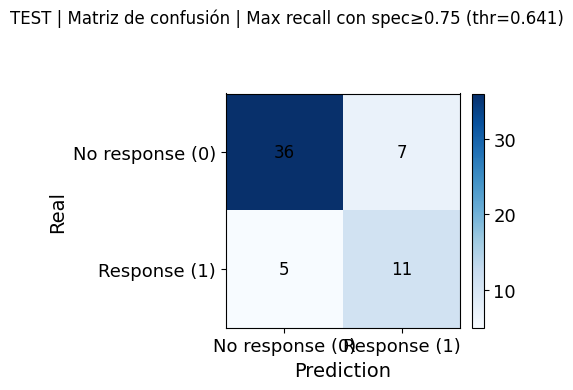

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, confusion_matrix,
    accuracy_score, recall_score
)

# ============================================================
# Threshold calibration and metrics on the test set
# ============================================================

def compute_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else np.nan

def metrics_at_threshold(y_true, y_prob, thr):
    y_pred = (y_prob >= thr).astype(int)
    acc = accuracy_score(y_true, y_pred)
    sens = recall_score(y_true, y_pred, pos_label=1)  # sensibilidad
    spec = compute_specificity(y_true, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return {
        "thr": float(thr),
        "accuracy": float(acc),
        "sensibilidad": float(sens),
        "especificidad": float(spec),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }

def threshold_youden(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    youden = tpr - fpr  # = sens + espec - 1
    k = int(np.argmax(youden))
    return float(thr[k]), float(youden[k]), float(tpr[k]), float(1 - fpr[k])

def threshold_max_recall_min_spec(y_true, y_prob, min_spec=0.75):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    spec = 1 - fpr
    valid = spec >= min_spec
    if not np.any(valid):
        # No existe threshold que cumpla la restricción
        return np.nan, None

    # Entre los válidos, escoger el de mayor recall (tpr).
    # Si hay empates, escoger el de mayor especificidad.
    idxs = np.where(valid)[0]
    best = idxs[np.lexsort((-spec[idxs], -tpr[idxs]))][0]
    return float(thr[best]), {"recall": float(tpr[best]), "spec": float(spec[best])}

def plot_confusion(y_true, y_prob, thr, title):
    y_pred = (y_prob >= thr).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])

    fig, ax = plt.subplots(figsize=(5,4))

    im = ax.imshow(cm, cmap="Blues")

    ax.set_xlabel("Prediction")
    ax.set_ylabel("Real")

    ax.set_xticks([0,1])
    ax.set_yticks([0,1])

    ax.set_xticklabels(["No response (0)", "Response (1)"])
    ax.set_yticklabels(["No response (0)", "Response (1)"])

    # números dentro de la matriz
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=12)

    # título de la figura (no del eje)
    fig.suptitle(title, fontsize=12)

    # colorbar bien posicionada
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout(rect=[0,0,1,0.92])  # deja espacio para el título
    plt.show()
# ============================================================
# 1) Asegurar que el modelo final esté entrenado
# ============================================================
p_test = final_model.predict_proba(X_test2)[:, 1]

# ============================================================
# 2) Umbrales
# ============================================================
thr_05 = 0.5

thr_y, youdenJ, youden_sens, youden_spec = threshold_youden(y_test, p_test)

thr_r75, info_r75 = threshold_max_recall_min_spec(y_test, p_test, min_spec=0.75)

print("[Umbrales en TEST]")
print(f"thr_0.5 = {thr_05:.3f}")
print(f"thr_youden = {thr_y:.6f} | J={youdenJ:.3f} | sens={youden_sens:.3f} | spec={youden_spec:.3f}")
if np.isnan(thr_r75):
    print("thr_max_recall_spec0.75 = NO EXISTE threshold con especificidad >= 0.75 en TEST")
else:
    print(f"thr_max_recall_spec0.75 = {thr_r75:.6f} | sens={info_r75['recall']:.3f} | spec={info_r75['spec']:.3f}")

# ============================================================
# 3) Métricas en TEST para cada threshold
# ============================================================
rows = []
rows.append({"threshold_name": "thr_0.5", **metrics_at_threshold(y_test, p_test, thr_05)})
rows.append({"threshold_name": "thr_youden", **metrics_at_threshold(y_test, p_test, thr_y)})

if not np.isnan(thr_r75):
    rows.append({"threshold_name": "thr_max_recall_spec0.75", **metrics_at_threshold(y_test, p_test, thr_r75)})

df_thr = pd.DataFrame(rows)[[
    "threshold_name", "thr", "accuracy", "sensibilidad", "especificidad", "TN", "FP", "FN", "TP"
]]
display(df_thr)

# ============================================================
# 4) Matrices de confusión (una figura por threshold)
# ============================================================
plot_confusion(y_test, p_test, thr_05, "TEST | Matriz de confusión | Umbral 0.5")
plot_confusion(y_test, p_test, thr_y,  f"TEST | Matriz de confusión | Youden (thr={thr_y:.3f})")

if not np.isnan(thr_r75):
    plot_confusion(y_test, p_test, thr_r75, f"TEST | Matriz de confusión | Max recall con spec≥0.75 (thr={thr_r75:.3f})")

,threshold_name,thr,accuracy,sensibilidad,especificidad,TN,FP,FN,TP
0,thr_0.5 (from TEST),0.500000,0.806452,0.777778,0.818182,18,4,2,7
1,thr_youden (from TEST),0.350471,0.741935,0.777778,0.727273,16,6,2,7
2,thr_max_recall_spec0.75 (from TEST),0.641492,0.870968,0.777778,0.909091,20,2,2,7


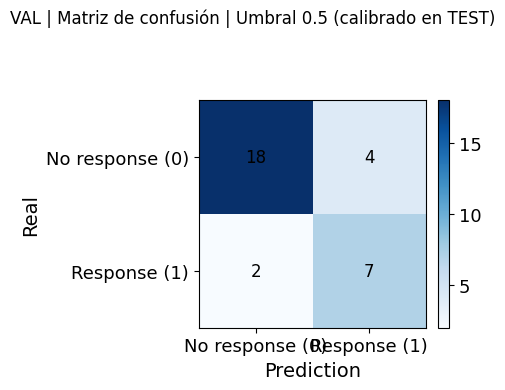

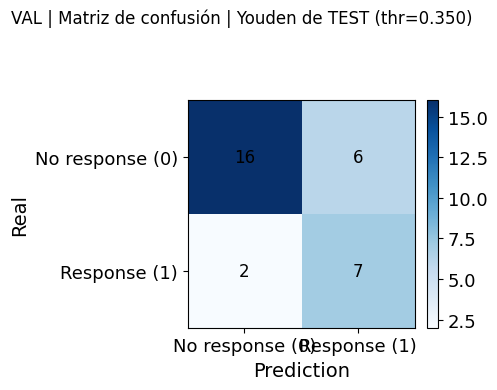

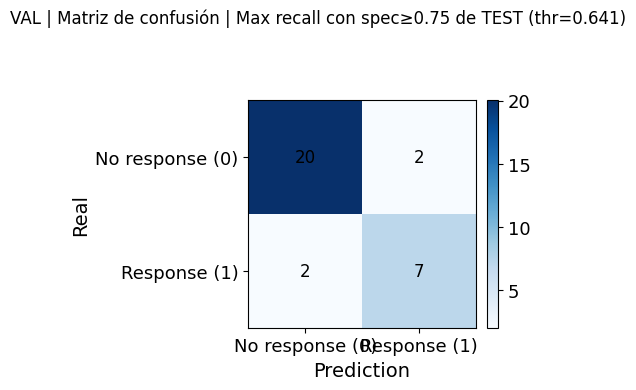

In [ ]:
# ============================================================
# Apply thresholds calibrated on TEST to the validation set
# ============================================================

# Predicted probabilities en VAL
p_val = final_model.predict_proba(X_val2)[:, 1]

# Métricas en VAL con thresholds de TEST
rows_val = []
rows_val.append({"threshold_name": "thr_0.5 (from TEST)", **metrics_at_threshold(y_val, p_val, thr_05)})
rows_val.append({"threshold_name": "thr_youden (from TEST)", **metrics_at_threshold(y_val, p_val, thr_y)})

if not np.isnan(thr_r75):
    rows_val.append({
        "threshold_name": "thr_max_recall_spec0.75 (from TEST)",
        **metrics_at_threshold(y_val, p_val, thr_r75)
    })

df_thr_val = pd.DataFrame(rows_val)[[
    "threshold_name", "thr", "accuracy", "sensibilidad", "especificidad", "TN", "FP", "FN", "TP"
]]
display(df_thr_val)

# Matrices de confusión en VAL (threshold fijo desde TEST)
plot_confusion(y_val, p_val, thr_05, "VAL | Matriz de confusión | Umbral 0.5 (calibrado en TEST)")
plot_confusion(y_val, p_val, thr_y,  f"VAL | Matriz de confusión | Youden de TEST (thr={thr_y:.3f})")

if not np.isnan(thr_r75):
    plot_confusion(
        y_val, p_val, thr_r75,
        f"VAL | Matriz de confusión | Max recall con spec≥0.75 de TEST (thr={thr_r75:.3f})"
    )
else:
    print("[INFO] No se grafica el threshold max_recall_spec0.75 en VAL porque no existió en TEST.")

,threshold_name,thr,accuracy,sensibilidad,especificidad,TN,FP,FN,TP
0,0.5,0.500000,0.806452,0.777778,0.818182,18,4,2,7
1,Youden index,0.350471,0.741935,0.777778,0.727273,16,6,2,7
2,Max recall with specificity ≥ 0.75,0.641492,0.870968,0.777778,0.909091,20,2,2,7


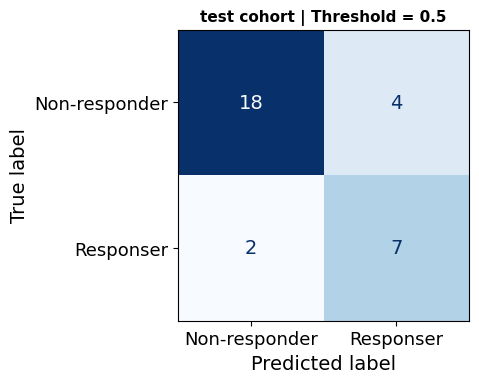

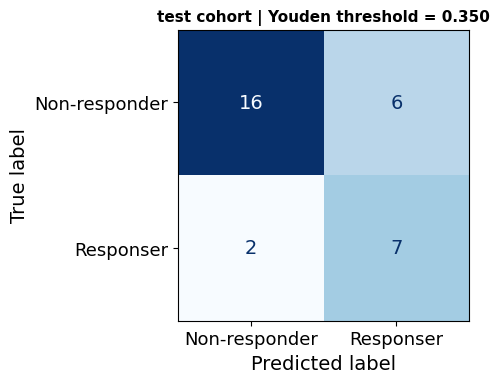

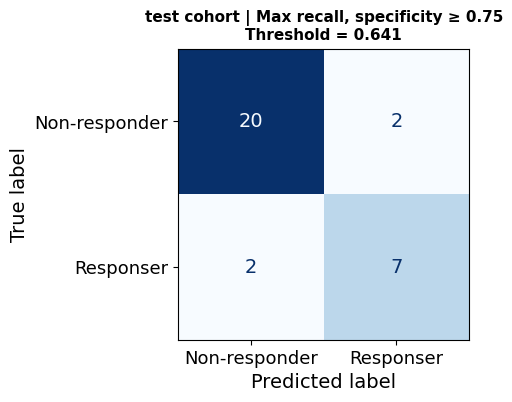

Archivos guardados en: figures_confusion_matrices


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Output directory
outdir = "figures_confusion_matrices"
os.makedirs(outdir, exist_ok=True)

# Predicted probabilities en VAL
p_val = final_model.predict_proba(X_val2)[:, 1]

# Función mejorada para guardar matriz
def save_confusion_matrix(y_true, y_prob, thr, title, filename):
    y_pred = (y_prob >= thr).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(5, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-responder", "Responser"]
    )
    disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    plt.tight_layout()

    png_path = os.path.join(outdir, f"{filename}.png")
    pdf_path = os.path.join(outdir, f"{filename}.pdf")

    plt.savefig(png_path, dpi=600, bbox_inches="tight")
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    plt.close()

    return cm, png_path, pdf_path


# Métricas en VAL con thresholds calibrados en TEST
rows_val = []

rows_val.append({
    "threshold_name": "0.5",
    **metrics_at_threshold(y_val, p_val, thr_05)
})

rows_val.append({
    "threshold_name": "Youden index",
    **metrics_at_threshold(y_val, p_val, thr_y)
})

if not np.isnan(thr_r75):
    rows_val.append({
        "threshold_name": "Max recall with specificity ≥ 0.75",
        **metrics_at_threshold(y_val, p_val, thr_r75)
    })

df_thr_val = pd.DataFrame(rows_val)[[
    "threshold_name", "thr", "accuracy", "sensibilidad",
    "especificidad", "TN", "FP", "FN", "TP"
]]

display(df_thr_val)

# Save figure tabla de métricas
df_thr_val.to_csv(
    os.path.join(outdir, "test_threshold_metrics.csv"),
    index=False
)

df_thr_val.to_excel(
    os.path.join(outdir, "test_threshold_metrics.xlsx"),
    index=False
)


# Matriz threshold 0.5
save_confusion_matrix(
    y_val, p_val, thr_05,
    "test cohort | Threshold = 0.5",
    "confusion_matrix_validation_thr_05"
)

# Matriz Youden
save_confusion_matrix(
    y_val, p_val, thr_y,
    f"test cohort | Youden threshold = {thr_y:.3f}",
    "confusion_matrix_validation_youden"
)

# Matriz especificidad ≥ 0.75
if not np.isnan(thr_r75):
    save_confusion_matrix(
        y_val, p_val, thr_r75,
        f"test cohort | Max recall, specificity ≥ 0.75\nThreshold = {thr_r75:.3f}",
        "confusion_matrix_validation_spec075"
    )
else:
    print("[INFO] No se grafica el threshold max_recall_spec0.75 porque no existió en TEST.")

print(f"Archivos guardados en: {outdir}")

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# Functions
# ============================================================

def compute_metrics(y_true, y_prob, threshold=0.5):
    """
    Calculate classification metrics.
    """

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= threshold).astype(int)

    auc = roc_auc_score(y_true, y_prob)

    accuracy = accuracy_score(y_true, y_pred)

    sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0,1]
    ).ravel()

    specificity = tn / (tn + fp)

    return {
        "AUC": auc,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1-score": f1
    }


# ============================================================
# Bootstrap
# ============================================================

def bootstrap_ci_metrics(
    y_true,
    y_prob,
    threshold=0.5,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    n = len(y_true)

    # Point estimates from the original dataset
    original = compute_metrics(
        y_true,
        y_prob,
        threshold
    )

    boot_metrics = []

    for i in range(n_bootstrap):

        idx = rng.choice(
            n,
            size=n,
            replace=True
        )

        yt = y_true[idx]
        yp = y_prob[idx]

        # Skip bootstrap samples containing only one class
        if len(np.unique(yt)) < 2:
            continue

        boot_metrics.append(
            compute_metrics(
                yt,
                yp,
                threshold
            )
        )

    boot_df = pd.DataFrame(boot_metrics)

    summary = []

    for metric in original.keys():

        lower = np.percentile(
            boot_df[metric],
            2.5
        )

        upper = np.percentile(
            boot_df[metric],
            97.5
        )

        summary.append({
            "Metric": metric,
            "Estimate": original[metric],
            "CI Lower": lower,
            "CI Upper": upper,
            "Estimate (95% CI)":
                f"{original[metric]:.3f} "
                f"({lower:.3f}-{upper:.3f})"
        })

    summary = pd.DataFrame(summary)

    return summary


# ============================================================
# TEST SET
# ============================================================

p_test = final_model.predict_proba(X_test2)[:,1]

summary_test = bootstrap_ci_metrics(
    y_true = y_test,
    y_prob=p_test,
    threshold=0.5,
    n_bootstrap=2000,
    random_state=42
)

summary_test["Dataset"] = "Test"


# ============================================================
# VALIDATION SET
# ============================================================

p_val = final_model.predict_proba(X_val2)[:,1]

summary_val = bootstrap_ci_metrics(
    y_true = y_val,
    y_prob=p_val,
    threshold=0.5,
    n_bootstrap=2000,
    random_state=43
)

summary_val["Dataset"] = "Validation"


# ============================================================
# Merge results
# ============================================================

summary_all = pd.concat(
    [
        summary_test,
        summary_val
    ],
    ignore_index=True
)

summary_all = summary_all[
    [
        "Dataset",
        "Metric",
        "Estimate",
        "CI Lower",
        "CI Upper",
        "Estimate (95% CI)"
    ]
]

print(summary_all)

display(summary_all)


# ============================================================
# Save results
# ============================================================

summary_all.to_csv(
    "Bootstrap_95CI_Test_Validation.csv",
    index=False
)

summary_all.to_excel(
    "Bootstrap_95CI_Test_Validation.xlsx",
    index=False
)

print("\nResults saved successfully.")

       Dataset       Metric  Estimate  CI Lower  CI Upper    Estimate (95% CI)
0         Test          AUC  0.841570  0.726953  0.940417  0.842 (0.727-0.940)
1         Test     Accuracy  0.762712  0.661017  0.864407  0.763 (0.661-0.864)
2         Test  Sensitivity  0.687500  0.444444  0.909091  0.688 (0.444-0.909)
3         Test  Specificity  0.790698  0.658521  0.909091  0.791 (0.659-0.909)
4         Test    Precision  0.550000  0.315789  0.777778  0.550 (0.316-0.778)
5         Test     F1-score  0.611111  0.400000  0.780488  0.611 (0.400-0.780)
6   Validation          AUC  0.803030  0.584583  0.964653  0.803 (0.585-0.965)
7   Validation     Accuracy  0.806452  0.677419  0.935484  0.806 (0.677-0.935)
8   Validation  Sensitivity  0.777778  0.444444  1.000000  0.778 (0.444-1.000)
9   Validation  Specificity  0.818182  0.650000  0.954545  0.818 (0.650-0.955)
10  Validation    Precision  0.636364  0.333333  0.909091  0.636 (0.333-0.909)
11  Validation     F1-score  0.700000  0.400000  0.8

,Dataset,Metric,Estimate,CI Lower,CI Upper,Estimate (95% CI)
0,Test,AUC,0.841570,0.726953,0.940417,0.842 (0.727-0.940)
1,Test,Accuracy,0.762712,0.661017,0.864407,0.763 (0.661-0.864)
2,Test,Sensitivity,0.687500,0.444444,0.909091,0.688 (0.444-0.909)
3,Test,Specificity,0.790698,0.658521,0.909091,0.791 (0.659-0.909)
4,Test,Precision,0.550000,0.315789,0.777778,0.550 (0.316-0.778)
5,Test,F1-score,0.611111,0.400000,0.780488,0.611 (0.400-0.780)
6,Validation,AUC,0.803030,0.584583,0.964653,0.803 (0.585-0.965)
7,Validation,Accuracy,0.806452,0.677419,0.935484,0.806 (0.677-0.935)
8,Validation,Sensitivity,0.777778,0.444444,1.000000,0.778 (0.444-1.000)
9,Validation,Specificity,0.818182,0.650000,0.954545,0.818 (0.650-0.955)



Results saved successfully.


Brier score: 0.160


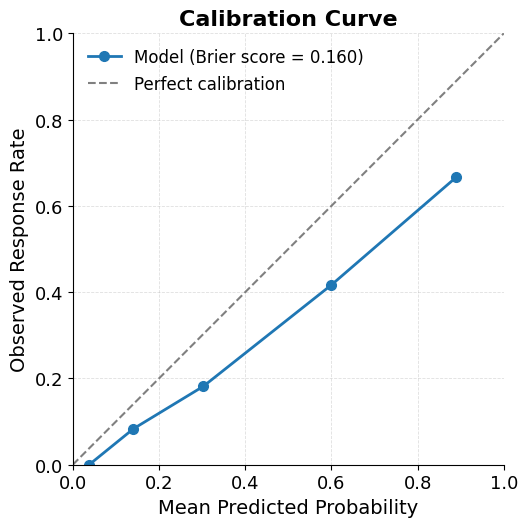

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# ==========================
# Publication-quality settings
# ==========================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12
})

# ==========================
# Predicted probabilities
# ==========================
y_test_prob = final_model.predict_proba(X_test2)[:, 1]

# ==========================
# Brier score
# ==========================
brier = brier_score_loss(y_test, y_test_prob)
print(f"Brier score: {brier:.3f}")

# ==========================
# Calibration curve
# ==========================
prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=5,
    strategy="quantile"
)

# ==========================
# Plot
# ==========================
fig, ax = plt.subplots(figsize=(5.5, 5.5))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    markersize=7,
    label=f"Model (Brier score = {brier:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Perfect calibration"
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Response Rate")
ax.set_title("Calibration Curve")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend(frameon=False, loc="upper left")

ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.4
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ==========================
# Save figure
# ==========================
plt.savefig(
    "Calibration_Curve_Test.tiff",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "raw"}
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample

# ============================================================
# Data used to train the final model
# ============================================================

X_train_or = X_traine2.copy()
y_train_or = np.asarray(y_traine)

selected_genes = X_train_or.columns

# ============================================================
# Fit the final model on the original training data
# ============================================================

final_model = LogisticRegression(
    C=0.1,
    solver='liblinear',
    max_iter=1000
)

final_model.fit(X_train_or, y_train_or)

# Coefficients from the final model
coef_original = final_model.coef_[0]

# Odds ratios from the final model
or_original = np.exp(coef_original)

# ============================================================
# Bootstrap coefficients
# ============================================================

n_bootstrap = 2000
random_state = 42
rng = np.random.default_rng(random_state)

boot_coefs = []

n = X_train_or.shape[0]

for i in range(n_bootstrap):

    # Resample patients with replacement
    idx = rng.choice(
        np.arange(n),
        size=n,
        replace=True
    )

    X_boot = X_train_or.iloc[idx]
    y_boot = y_train_or[idx]

    # Skip bootstrap samples with only one class
    if len(np.unique(y_boot)) < 2:
        continue

    model_boot = LogisticRegression(
        C=0.1,
        solver='liblinear',
        max_iter=1000
    )

    model_boot.fit(X_boot, y_boot)

    boot_coefs.append(model_boot.coef_[0])

boot_coefs = np.array(boot_coefs)

# Convert bootstrap coefficients to OR
boot_or = np.exp(boot_coefs)

# ============================================================
# 95% confidence intervals
# ============================================================

or_ci_lower = np.percentile(boot_or, 2.5, axis=0)
or_ci_upper = np.percentile(boot_or, 97.5, axis=0)

# ============================================================
# Create results table
# ============================================================

or_table = pd.DataFrame({
    "Gene": selected_genes,
    "Coefficient": coef_original,
    "OR": or_original,
    "CI_lower": or_ci_lower,
    "CI_upper": or_ci_upper
})

# Direction of association
or_table["Direction"] = np.where(
    or_table["OR"] > 1,
    "Associated with response",
    "Associated with non-response"
)

# Formatted column for manuscript
or_table["OR (95% CI)"] = or_table.apply(
    lambda x: f"{x['OR']:.2f} ({x['CI_lower']:.2f}-{x['CI_upper']:.2f})",
    axis=1
)

# Sort by absolute coefficient magnitude
or_table["abs_coefficient"] = or_table["Coefficient"].abs()

or_table = or_table.sort_values(
    "abs_coefficient",
    ascending=False
)

# Final table
or_table_final = or_table[
    [
        "Gene",
        "Coefficient",
        "OR",
        "CI_lower",
        "CI_upper",
        "OR (95% CI)",
        "Direction"
    ]
]

display(or_table_final)

# ============================================================
# Save table
# ============================================================

or_table_final.to_csv(
    "Logistic_Regression_OR_95CI_bootstrap.csv",
    index=False
)

or_table_final.to_excel(
    "Logistic_Regression_OR_95CI_bootstrap.xlsx",
    index=False
)

print("OR table saved successfully.")

,Gene,Coefficient,OR,CI_lower,CI_upper,OR (95% CI),Direction
7,RNASEH2A,-0.726789,0.483459,0.389706,0.619122,0.48 (0.39-0.62),Associated with non-response
17,TVP23B,0.595888,1.814641,1.441481,2.275896,1.81 (1.44-2.28),Associated with response
2,PAPLN,-0.593031,0.552650,0.446025,0.659433,0.55 (0.45-0.66),Associated with non-response
15,KLRC1,0.562079,1.754315,1.374779,2.242141,1.75 (1.37-2.24),Associated with response
3,ZNF649,-0.548100,0.578047,0.469823,0.706279,0.58 (0.47-0.71),Associated with non-response
0,SLC6A12,0.543572,1.722148,1.462971,2.069304,1.72 (1.46-2.07),Associated with response
21,BIRC2,-0.523555,0.592411,0.467186,0.774745,0.59 (0.47-0.77),Associated with non-response
26,PGBD2,0.502126,1.652230,1.275445,2.068000,1.65 (1.28-2.07),Associated with response
24,LOC124904912,-0.494748,0.609724,0.476850,0.762005,0.61 (0.48-0.76),Associated with non-response
5,CTAGE15,-0.475573,0.621529,0.501842,0.741208,0.62 (0.50-0.74),Associated with non-response


OR table saved successfully.


In [ ]:
# Starting from the final odds-ratio table

or_table_nr = or_table_final.copy()

# Odds ratios for non-response
or_table_nr["OR_non_response"] = 1 / or_table_nr["OR"]
or_table_nr["CI_lower_non_response"] = 1 / or_table_nr["CI_upper"]
or_table_nr["CI_upper_non_response"] = 1 / or_table_nr["CI_lower"]

# Interpret direction as increased risk of non-response
or_table_nr["Direction_non_response"] = np.where(
    or_table_nr["OR_non_response"] > 1,
    "Associated with non-response",
    "Associated with response"
)

# Manuscript-ready formatting
or_table_nr["OR for non-response (95% CI)"] = or_table_nr.apply(
    lambda x: f"{x['OR_non_response']:.2f} "
              f"({x['CI_lower_non_response']:.2f}-{x['CI_upper_non_response']:.2f})",
    axis=1
)

# Tabla final
or_table_nr_final = or_table_nr[
    [
        "Gene",
        "Coefficient",
        "OR_non_response",
        "CI_lower_non_response",
        "CI_upper_non_response",
        "OR for non-response (95% CI)",
        "Direction_non_response"
    ]
]

display(or_table_nr_final)

# Save figure
or_table_nr_final.to_csv(
    "Logistic_Regression_OR_for_NonResponse_95CI.csv",
    index=False
)

or_table_nr_final.to_excel(
    "Logistic_Regression_OR_for_NonResponse_95CI.xlsx",
    index=False
)

,Gene,Coefficient,OR_non_response,CI_lower_non_response,CI_upper_non_response,OR for non-response (95% CI),Direction_non_response
7,RNASEH2A,-0.726789,2.068428,1.615190,2.566040,2.07 (1.62-2.57),Associated with non-response
17,TVP23B,0.595888,0.551073,0.439387,0.693731,0.55 (0.44-0.69),Associated with response
2,PAPLN,-0.593031,1.809465,1.516454,2.242028,1.81 (1.52-2.24),Associated with non-response
15,KLRC1,0.562079,0.570023,0.446002,0.727390,0.57 (0.45-0.73),Associated with response
3,ZNF649,-0.548100,1.729963,1.415871,2.128459,1.73 (1.42-2.13),Associated with non-response
0,SLC6A12,0.543572,0.580670,0.483254,0.683540,0.58 (0.48-0.68),Associated with response
21,BIRC2,-0.523555,1.688017,1.290747,2.140474,1.69 (1.29-2.14),Associated with non-response
26,PGBD2,0.502126,0.605243,0.483559,0.784040,0.61 (0.48-0.78),Associated with response
24,LOC124904912,-0.494748,1.640086,1.312328,2.097095,1.64 (1.31-2.10),Associated with non-response
5,CTAGE15,-0.475573,1.608936,1.349149,1.992660,1.61 (1.35-1.99),Associated with non-response


## 13. Generalization Analysis of the LRM51 Model Using a Leave-One-Cancer-Type-Out Approach

In [ ]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE


# ============================================================
# 1. Get cancer type from clinical metadata using run_accession
# ============================================================

def get_cancer_type_for_matrix(X, clinical_metadata):

    clinical = clinical_metadata.copy()

    # Standardize sample identifiers
    clinical["id_normalizado"] = (
        clinical["run_accession"]
        .astype(str)
        .str.strip()
        .str.replace("/", ".", regex=False)
    )

    ids_X = (
        pd.Index(X.index.astype(str))
        .str.strip()
        .str.replace("/", ".", regex=False)
    )

    # Check for ambiguous identifiers
    if clinical["id_normalizado"].duplicated().any():
        raise ValueError(
            "Hay identificadores duplicados en clinical_metadata."
        )

    clinical = clinical.set_index("id_normalizado")

    # Check missing samples
    missing = ids_X[~ids_X.isin(clinical.index)]

    if len(missing) > 0:
        raise ValueError(
            f"Hay {len(missing)} muestras sin correspondencia. "
            f"Ejemplos: {missing[:10].tolist()}"
        )

    return pd.Series(
        clinical.loc[ids_X, "Tipo"].to_numpy(),
        index=X.index,
        name="Tipo"
    )

cancer_type_train = get_cancer_type_for_matrix(X_train2, clinical_metadata)
cancer_type_validation   = get_cancer_type_for_matrix(X_val2, clinical_metadata)
cancer_type_test  = get_cancer_type_for_matrix(X_test2, clinical_metadata)


# ============================================================
# 2. Training pool: TRAIN + VALIDATION only
# ============================================================

X_train_pool = pd.concat([X_train2, X_val2], axis=0)

y_train_pool = pd.concat([
    pd.Series(y_train, index=X_train2.index),
    pd.Series(y_val, index=X_val2.index)
], axis=0)

tipo_train_pool = pd.concat([cancer_type_train, cancer_type_validation], axis=0)


# ============================================================
# 3. Evaluation pool: TRAIN + VALIDATION + TEST
#    Only to evaluate all samples of the excluded cancer type
# ============================================================

X_eval_pool = pd.concat([X_train2, X_val2, X_test2], axis=0)

y_eval_pool = pd.concat([
    pd.Series(y_train, index=X_train2.index),
    pd.Series(y_val, index=X_val2.index),
    pd.Series(y_test, index=X_test2.index)
], axis=0)

tipo_eval_pool = pd.concat([cancer_type_train, cancer_type_validation, cancer_type_test], axis=0)


# Checks
assert all(X_train_pool.index == y_train_pool.index)
assert all(X_train_pool.index == tipo_train_pool.index)

assert all(X_eval_pool.index == y_eval_pool.index)
assert all(X_eval_pool.index == tipo_eval_pool.index)

print("Training pool:", X_train_pool.shape)
print(tipo_train_pool.value_counts())

print("\nEvaluation pool:", X_eval_pool.shape)
print(tipo_eval_pool.value_counts())


# ============================================================
# 4. Metric functions
# ============================================================

def compute_metrics(y_true, y_prob, threshold=0.5):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= threshold).astype(int)

    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan

    accuracy = accuracy_score(y_true, y_pred)

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    return {
        "AUC": auc,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1-score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


def bootstrap_ci_metrics(
    y_true,
    y_prob,
    threshold=0.5,
    n_bootstrap=2000,
    seed=42
):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    n = len(y_true)
    rng = np.random.default_rng(seed)

    boot_results = []
    invalid_iterations = 0

    for _ in range(n_bootstrap):

        idx = rng.choice(
            np.arange(n),
            size=n,
            replace=True
        )

        yt = y_true[idx]
        yp = y_prob[idx]

        # Exclude resamples containing only one class
        if len(np.unique(yt)) < 2:
            invalid_iterations += 1
            continue

        boot_results.append(
            compute_metrics(
                yt,
                yp,
                threshold=threshold
            )
        )

    valid_iterations = len(boot_results)

    ci = {
        "Bootstrap attempted": n_bootstrap,
        "Bootstrap valid": valid_iterations,
        "Bootstrap invalid": invalid_iterations,
        "Bootstrap valid (%)": (
            100 * valid_iterations / n_bootstrap
        )
    }

    metrics_list = [
        "AUC",
        "Accuracy",
        "Balanced Accuracy",
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1-score"
    ]

    if valid_iterations == 0:
        for metric in metrics_list:
            ci[f"{metric}_CI_lower"] = np.nan
            ci[f"{metric}_CI_upper"] = np.nan
        return ci

    boot_df = pd.DataFrame(boot_results)

    for metric in metrics_list:
        ci[f"{metric}_CI_lower"] = np.nanpercentile(
            boot_df[metric], 2.5
        )
        ci[f"{metric}_CI_upper"] = np.nanpercentile(
            boot_df[metric], 97.5
        )

    return ci

# ============================================================
# 5. Leave-one-cancer-type generalization analysis
# ============================================================

results = []

for cancer_type in tipo_eval_pool.unique():

    print(f"\nProcessing excluded cancer type: {cancer_type}")

    # Train only on TRAIN + VAL, excluding this cancer type
    train_mask = tipo_train_pool != cancer_type

    X_train_cv = X_train_pool.loc[train_mask]
    y_train_cv = y_train_pool.loc[train_mask]

    # Evaluate on ALL available samples of the excluded cancer type
    test_mask = tipo_eval_pool == cancer_type

    X_test_cv = X_eval_pool.loc[test_mask]
    y_test_cv = y_eval_pool.loc[test_mask]

    if len(np.unique(y_train_cv)) < 2:
        print(f"Skipping {cancer_type}: training set has only one class.")
        continue

    # SMOTE only on training raw_counts
    class_counts = pd.Series(y_train_cv).value_counts()
    minority_count = class_counts.min()

    if minority_count > 1:
        smote = SMOTE(
            random_state=42,
            k_neighbors=min(5, minority_count - 1)
        )

        X_train_resampled, y_train_resampled = smote.fit_resample(
            X_train_cv,
            y_train_cv
        )
    else:
        X_train_resampled = X_train_cv
        y_train_resampled = y_train_cv

    # Train Logistic Regression
    model = LogisticRegression(
        C=0.1,
        solver="liblinear",
        max_iter=1000
    )

    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Probability of response
    y_prob_cv = model.predict_proba(X_test_cv)[:, 1]

    # Point estimates
    metrics = compute_metrics(
        y_true = y_test_cv,
        y_prob = y_prob_cv,
        threshold=0.5
    )

    # Bootstrap 95% CI
    ci_metrics = bootstrap_ci_metrics(
        y_true = y_test_cv,
        y_prob = y_prob_cv,
        threshold=0.5,
        n_bootstrap=2000,
        seed=42
    )

    results.append({
        "Cancer type": cancer_type,
        "n": len(y_test_cv),
        "Responsers": int(np.sum(y_test_cv == 1)),
        "Non-responders": int(np.sum(y_test_cv == 0)),
        **metrics,
        **ci_metrics
    })


# ============================================================
# 6. Results table for manuscript
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="AUC",
    ascending=False,
    na_position="last"
)

for metric in [
    "AUC",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity"
]:
    results_df[f"{metric} (95% CI)"] = results_df.apply(
        lambda x: (
            f"{x[metric]:.3f} "
            f"({x[f'{metric}_CI_lower']:.3f}-{x[f'{metric}_CI_upper']:.3f})"
        ),
        axis=1
    )

main_table = results_df[
    [
        "Cancer type",
        "n",
        "Responsers",
        "Non-responders",
        "AUC (95% CI)",
        "Balanced Accuracy (95% CI)",
        "Sensitivity (95% CI)",
        "Specificity (95% CI)"
    ]
]

print("\nMain table for manuscript\n")
print(main_table)

display(main_table)


# ============================================================
# 7. Full supplementary table
# ============================================================

for metric in [
    "Accuracy",
    "Precision",
    "F1-score"
]:
    results_df[f"{metric} (95% CI)"] = results_df.apply(
        lambda x: (
            f"{x[metric]:.3f} "
            f"({x[f'{metric}_CI_lower']:.3f}-{x[f'{metric}_CI_upper']:.3f})"
        ),
        axis=1
    )

supplementary_table = results_df[
    [
        "Cancer type",
        "n",
        "Responsers",
        "Non-responders",
        "AUC (95% CI)",
        "Accuracy (95% CI)",
        "Balanced Accuracy (95% CI)",
        "Sensitivity (95% CI)",
        "Specificity (95% CI)",
        "Precision (95% CI)",
        "F1-score (95% CI)",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
]

print("\nSupplementary table\n")
print(supplementary_table)

display(supplementary_table)


# ============================================================
# 8. Save tables
# ============================================================

main_table.to_csv(
    "Leave_One_Cancer_Type_Main_Table.csv",
    index=False
)

main_table.to_excel(
    "Leave_One_Cancer_Type_Main_Table.xlsx",
    index=False
)

supplementary_table.to_csv(
    "Leave_One_Cancer_Type_Supplementary_Table.csv",
    index=False
)

supplementary_table.to_excel(
    "Leave_One_Cancer_Type_Supplementary_Table.xlsx",
    index=False
)

print("\nAnalysis completed and tables saved.")

Training pool: (555, 51)
Tipo
Urothelial    272
Melanoma      120
Renal          70
Gastric        39
Lung           37
Oral           10
Thymic          7
Name: count, dtype: int64

Evaluation pool: (614, 51)
Tipo
Urothelial    296
Melanoma      134
Renal          80
Lung           43
Gastric        42
Oral           11
Thymic          8
Name: count, dtype: int64

Processing excluded cancer type: Melanoma

Processing excluded cancer type: Urothelial

Processing excluded cancer type: Gastric

Processing excluded cancer type: Renal

Processing excluded cancer type: Oral

Processing excluded cancer type: Lung

Processing excluded cancer type: Thymic

Main table for manuscript

  Cancer type    n  Responsers  Non-responders         AUC (95% CI)  \
4        Oral   11           3               8  1.000 (1.000-1.000)   
2     Gastric   42          11              31  0.962 (0.869-1.000)   
6      Thymic    8           4               4  0.938 (0.667-1.000)   
5        Lung   43          13  

,Cancer type,n,Responsers,Non-responders,AUC (95% CI),Balanced Accuracy (95% CI),Sensitivity (95% CI),Specificity (95% CI)
4,Oral,11,3,8,1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000)
2,Gastric,42,11,31,0.962 (0.869-1.000),0.906 (0.787-0.985),0.909 (0.700-1.000),0.903 (0.788-1.000)
6,Thymic,8,4,4,0.938 (0.667-1.000),0.875 (0.625-1.000),1.000 (1.000-1.000),0.750 (0.250-1.000)
5,Lung,43,13,30,0.903 (0.769-1.000),0.846 (0.700-0.962),0.692 (0.400-0.923),1.000 (1.000-1.000)
3,Renal,80,20,60,0.818 (0.708-0.913),0.675 (0.566-0.791),0.400 (0.188-0.632),0.950 (0.885-1.000)
1,Urothelial,296,68,228,0.807 (0.747-0.861),0.695 (0.632-0.757),0.544 (0.429-0.662),0.846 (0.797-0.890)
0,Melanoma,134,50,84,0.778 (0.691-0.852),0.621 (0.569-0.672),0.980 (0.933-1.000),0.262 (0.170-0.358)



Supplementary table

  Cancer type    n  Responsers  Non-responders         AUC (95% CI)  \
4        Oral   11           3               8  1.000 (1.000-1.000)   
2     Gastric   42          11              31  0.962 (0.869-1.000)   
6      Thymic    8           4               4  0.938 (0.667-1.000)   
5        Lung   43          13              30  0.903 (0.769-1.000)   
3       Renal   80          20              60  0.818 (0.708-0.913)   
1  Urothelial  296          68             228  0.807 (0.747-0.861)   
0    Melanoma  134          50              84  0.778 (0.691-0.852)   

     Accuracy (95% CI) Balanced Accuracy (95% CI) Sensitivity (95% CI)  \
4  1.000 (1.000-1.000)        1.000 (1.000-1.000)  1.000 (1.000-1.000)   
2  0.905 (0.810-0.976)        0.906 (0.787-0.985)  0.909 (0.700-1.000)   
6  0.875 (0.625-1.000)        0.875 (0.625-1.000)  1.000 (1.000-1.000)   
5  0.907 (0.814-0.977)        0.846 (0.700-0.962)  0.692 (0.400-0.923)   
3  0.812 (0.725-0.887)        0.675 (0.

,Cancer type,n,Responsers,Non-responders,AUC (95% CI),Accuracy (95% CI),Balanced Accuracy (95% CI),Sensitivity (95% CI),Specificity (95% CI),Precision (95% CI),F1-score (95% CI),TN,FP,FN,TP
4,Oral,11,3,8,1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),1.000 (1.000-1.000),8,0,0,3
2,Gastric,42,11,31,0.962 (0.869-1.000),0.905 (0.810-0.976),0.906 (0.787-0.985),0.909 (0.700-1.000),0.903 (0.788-1.000),0.769 (0.500-1.000),0.833 (0.625-0.966),28,3,1,10
6,Thymic,8,4,4,0.938 (0.667-1.000),0.875 (0.625-1.000),0.875 (0.625-1.000),1.000 (1.000-1.000),0.750 (0.250-1.000),0.800 (0.333-1.000),0.889 (0.500-1.000),3,1,0,4
5,Lung,43,13,30,0.903 (0.769-1.000),0.907 (0.814-0.977),0.846 (0.700-0.962),0.692 (0.400-0.923),1.000 (1.000-1.000),1.000 (1.000-1.000),0.818 (0.571-0.960),30,0,4,9
3,Renal,80,20,60,0.818 (0.708-0.913),0.812 (0.725-0.887),0.675 (0.566-0.791),0.400 (0.188-0.632),0.950 (0.885-1.000),0.727 (0.429-1.000),0.516 (0.273-0.710),57,3,12,8
1,Urothelial,296,68,228,0.807 (0.747-0.861),0.777 (0.726-0.824),0.695 (0.632-0.757),0.544 (0.429-0.662),0.846 (0.797-0.890),0.514 (0.397-0.620),0.529 (0.426-0.619),193,35,31,37
0,Melanoma,134,50,84,0.778 (0.691-0.852),0.530 (0.440-0.619),0.621 (0.569-0.672),0.980 (0.933-1.000),0.262 (0.170-0.358),0.441 (0.345-0.536),0.609 (0.510-0.695),22,62,1,49



Analysis completed and tables saved.


In [ ]:

columnas = [
    "Cancer type",
    "n",
    "Responsers",
    "Non-responders",
    "Bootstrap attempted",
    "Bootstrap valid",
    "Bootstrap invalid",
    "Bootstrap valid (%)"
]

display(results_df[columnas])


,Cancer type,n,Responsers,Non-responders,Bootstrap attempted,Bootstrap valid,Bootstrap invalid,Bootstrap valid (%)
4,Oral,11,3,8,2000,1936,64,96.80
2,Gastric,42,11,31,2000,2000,0,100.00
6,Thymic,8,4,4,2000,1985,15,99.25
5,Lung,43,13,30,2000,2000,0,100.00
3,Renal,80,20,60,2000,2000,0,100.00
1,Urothelial,296,68,228,2000,2000,0,100.00
0,Melanoma,134,50,84,2000,2000,0,100.00


## 14. Cancer/study baselines (held-out TEST)



This additional analysis compares **cancer-only**, **study-only**, **cancer + study**, **prevalence-only**, and **LRM51** on the **same original held-out test set**. It does not change the original model or feature selection. Fit categorical encoders and baseline models on TRAIN only. Do not use TEST for tuning. The study and cancer fields are correlated, so interpret joint coefficients cautiously. This is an internal test comparison, not independent validation of gene discovery.

**Prerequisites:** run the notebook through the final LRM51 training (cell 89), including loading metadata and original splits. The `Base` field is assumed to identify study/author; verify that mapping before reporting results. The baseline classifiers use natural class prevalence (no SMOTE); LRM51 uses its original SMOTE training. This distinction is reported explicitly. AUC for prevalence-only is 0.5 when both test classes are present.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, brier_score_loss,
                             accuracy_score)

required = {'run_accession', 'Tipo', 'Base'}
missing = required.difference(clinical_metadata.columns)
if missing:
    raise ValueError(f"Missing metadata columns: {missing}. Inspect clinical_metadata.columns")

meta = clinical_metadata.copy()
meta['sample_id'] = (meta['run_accession'].astype(str).str.strip()
                     .str.replace('/', '.', regex=False))
if meta['sample_id'].duplicated().any():
    raise ValueError('Duplicated sample IDs in metadata; resolve before comparing baselines')
meta = meta.set_index('sample_id')

# Confirm all test and train IDs map exactly to metadata
for partition_name, X in [('TRAIN', X_train2), ('TEST', X_test2)]:
    unmatched = X.index.difference(meta.index)
    if len(unmatched):
        raise ValueError(f'{partition_name}: {len(unmatched)} sample IDs absent from metadata: {list(unmatched[:10])}')

meta_train = meta.reindex(X_train2.index)[['Tipo', 'Base']].copy()
meta_test = meta.reindex(X_test2.index)[['Tipo', 'Base']].copy()
for frame in (meta_train, meta_test):
    if frame.isna().any().any() or (frame.astype(str).apply(lambda c: c.str.strip() == '')).any().any():
        raise ValueError('Missing cancer or study label: inspect metadata before fitting')

assert len(X_train2) == len(y_train) and len(X_test2) == len(y_test)
assert list(X_train2.columns) == list(X_test2.columns)
print('TRAIN:', len(y_train), 'TEST:', len(y_test))
print('Studies:', sorted(meta_train['Base'].unique()))
print('Cancer types:', sorted(meta_train['Tipo'].unique()))
print('TEST unseen study categories:', set(meta_test['Base']) - set(meta_train['Base']))
print('TEST unseen cancer categories:', set(meta_test['Tipo']) - set(meta_train['Tipo']))
print('Check study/author mapping in Base before interpreting results.')


TRAIN: 524 TEST: 59
Studies: ['Auslander', 'CHO', 'Der', 'GAO', 'GIDE', 'HE', 'HUGO', 'KIM', 'KIM2', 'Liu', 'Mariathasan', 'McDermott', 'RIAZ']
Cancer types: ['Gastric', 'Lung', 'Melanoma', 'Oral', 'Renal', 'Thymic', 'Urothelial']
TEST unseen study categories: set()
TEST unseen cancer categories: set()
Check study/author mapping in Base before interpreting results.


In [ ]:
# Fit TRAIN-only reference models and compare on the identical TEST set.
# Logistic baselines are intentionally trained WITHOUT SMOTE, to estimate
# information in categorical covariates at the observed class prevalence.
# Original LRM51 is reused as fitted (its training used SMOTE).

def baseline_model(columns):
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:  # older sklearn
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return Pipeline([
        ('encode', ColumnTransformer([('categorical', encoder, columns)], remainder='drop')),
        ('classifier', LogisticRegression(C=0.1, solver='liblinear', max_iter=1000))
    ])

predictions = {}
prevalence = float(np.mean(y_train))
predictions['Prevalence-only'] = np.repeat(prevalence, len(y_test))

for name, cols in [
    ('Cancer-only', ['Tipo']),
    ('Study-only', ['Base']),
    ('Cancer + Study', ['Tipo', 'Base'])
]:
    fitted = baseline_model(cols)
    fitted.fit(meta_train, y_train)
    predictions[name] = fitted.predict_proba(meta_test)[:, 1]

# LRM51 original model, no refitting and no changes to its training.
predictions['LRM51'] = final_model.predict_proba(X_test2)[:, 1]

rows = []
for name, prob in predictions.items():
    yhat = (np.asarray(prob) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yhat, labels=[0, 1]).ravel()
    rows.append({
        'Model': name, 'n_test': len(y_test),
        'AUC': roc_auc_score(y_test, prob),
        'Balanced accuracy': balanced_accuracy_score(y_test, yhat),
        'Sensitivity': recall_score(y_test, yhat, zero_division=0),
        'Specificity': tn / (tn + fp) if tn + fp else np.nan,
        'Brier': brier_score_loss(y_test, prob),
        'Accuracy': accuracy_score(y_test, yhat),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })
comparison_comment9 = pd.DataFrame(rows).set_index('Model')
display(comparison_comment9.round(4))
comparison_comment9.to_csv('comment9_baseline_comparison_test.csv')
print('Saved: comment9_baseline_comparison_test.csv')


,n_test,AUC,Balanced accuracy,Sensitivity,Specificity,Brier,Accuracy,TN,FP,FN,TP
Model,,,,,,,,,,,
Prevalence-only,59,0.5000,0.5000,0.0000,1.0000,0.1977,0.7288,43,0,16,0
Cancer-only,59,0.4804,0.5000,0.0000,1.0000,0.2036,0.7288,43,0,16,0
Study-only,59,0.5022,0.5000,0.0000,1.0000,0.2000,0.7288,43,0,16,0
Cancer + Study,59,0.4978,0.5000,0.0000,1.0000,0.2003,0.7288,43,0,16,0
LRM51,59,0.8416,0.7391,0.6875,0.7907,0.1600,0.7627,34,9,5,11


Saved: comment9_baseline_comparison_test.csv


Interpretation and limits

- Compare LRM51 AUC and Brier against cancer-only, study-only, and joint baselines. The prevalence-only AUC is 0.5 by construction, but its Brier score is informative.
- Because each baseline is fitted using the original TRAIN and assessed on the original TEST, there is no TEST-set fitting or threshold optimization.
- Study and cancer may be partially or completely confounded; check the crosstab below.
- This comparison **does not** replace the reviewer's request for **gene-level associations adjusted for cancer and study**; that requires a separate multivariable analysis and careful consideration of collinearity/multiple testing.
- The LRM51 51-gene signature was selected earlier using global preprocessing during discovery; this comparison does not remove that historical limitation.


In [ ]:
# Check cancer/study overlap (confounding) and save the exact TEST predictions.
display(pd.crosstab(meta_train['Base'], meta_train['Tipo']))
output = pd.DataFrame({'sample_id': X_test2.index, 'response': y_test,
                       'cancer_type': meta_test['Tipo'].to_numpy(),
                       'study': meta_test['Base'].to_numpy()})
for name, probs in predictions.items():
    output['p_' + name.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')] = probs
output.to_csv('comment9_test_predictions.csv', index=False)
print('Saved: comment9_test_predictions.csv')


Tipo,Gastric,Lung,Melanoma,Oral,Renal,Thymic,Urothelial
Base,,,,,,,
Auslander,0,0,5,0,0,0,0
CHO,0,12,0,0,0,0,0
Der,0,0,0,0,22,0,0
GAO,0,0,8,0,0,0,0
GIDE,0,0,37,0,0,0,0
HE,0,0,0,0,0,7,0
HUGO,0,0,23,0,0,0,0
KIM,0,21,0,0,0,0,0
KIM2,38,0,0,0,0,0,0


Saved: comment9_test_predictions.csv


## 16. Exploratory Analysis of Gene–Response Associations Adjusted for Cancer Type and Study of Origin

 This is an *additional exploratory sensitivity analysis*, not a replacement for the original LRM51. It uses the original TRAIN and TEST partitions. The TEST set is used once for comparison, not for tuning.

- Compare the categorical cancer/study baseline against **cancer + study + 51 genes** to assess incremental transcriptomic predictive value.
- Fit a separate **one-gene-at-a-time logistic regression adjusted for cancer and study**, using TRAIN only, with a fixed L2 penalty. Report adjusted conditional odds ratios as descriptive estimates, **not inferential p-values**.
- Check whether cancer and study are strongly coupled; if so, separate their independent effects may not be identifiable.
- Do not interpret conditional gene associations as causal or independent external validation. The 51 genes were selected previously, so post-selection estimates may be optimistic.

The additional combined model and gene-specific adjusted models are new analyses; they are **not** the original LRM51 and their coefficients should not replace Table S1.


In [ ]:
# Incremental predictive information beyond cancer and study (fixed settings, TRAIN -> TEST)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
import numpy as np
import pandas as pd

genes = list(X_train2.columns)
assert len(genes) == 51, f"Expected 51 genes; found {len(genes)}"
assert meta_train.index.equals(X_train2.index)
assert meta_test.index.equals(X_test2.index)
assert np.isfinite(X_train2.to_numpy(dtype=float)).all()
assert np.isfinite(X_test2.to_numpy(dtype=float)).all()

# The 51-gene model's inputs are already log2(CPM+1); do not normalize again.
aug_train = pd.concat([meta_train, X_train2], axis=1)
aug_test = pd.concat([meta_test, X_test2], axis=1)

def encoder_compatible():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

combined = Pipeline([
    ('features', ColumnTransformer([
        ('categories', encoder_compatible(), ['Tipo', 'Base']),
        ('genes', StandardScaler(), genes)
    ])),
    ('logreg', LogisticRegression(C=0.1, solver='liblinear', max_iter=2000))
])
combined.fit(aug_train, y_train)
p_combined = combined.predict_proba(aug_test)[:, 1]

p_categories = predictions['Cancer + Study']
p_genes = predictions['LRM51']
incremental_results = pd.DataFrame([
    {'Model':'Cancer + Study', 'AUC':roc_auc_score(y_test,p_categories),
     'Brier':brier_score_loss(y_test,p_categories)},
    {'Model':'LRM51 (original)', 'AUC':roc_auc_score(y_test,p_genes),
     'Brier':brier_score_loss(y_test,p_genes)},
    {'Model':'Cancer + Study + 51 genes (new)', 'AUC':roc_auc_score(y_test,p_combined),
     'Brier':brier_score_loss(y_test,p_combined)}
])
display(incremental_results.round(4))
incremental_results.to_csv('comment9_incremental_value.csv', index=False)
pd.DataFrame({'sample_id':X_test2.index,'response':y_test,
              'p_cancer_study':p_categories,'p_LRM51':p_genes,
              'p_cancer_study_genes':p_combined}).to_csv(
                  'comment9_incremental_predictions.csv',index=False)
print('Saved incremental comparison and aligned test predictions.')


,Model,AUC,Brier
0,Cancer + Study,0.4978,0.2003
1,LRM51 (original),0.8416,0.1600
2,Cancer + Study + 51 genes (new),0.8474,0.1406


Saved incremental comparison and aligned test predictions.


In [ ]:
# Descriptive TRAIN-only gene associations, adjusted simultaneously for cancer and study.
# One gene at a time, with all cancer/study categories. Penalization prevents singular
# fits but DOES NOT resolve structural confounding or justify classical p-values.
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

adjusted_rows = []
for gene in genes:
    gene_pipeline = Pipeline([
        ('features', ColumnTransformer([
            ('categories', encoder_compatible(), ['Tipo','Base']),
            ('gene', StandardScaler(), [gene])
        ])),
        ('logreg', LogisticRegression(C=0.1, solver='liblinear', max_iter=2000))
    ])
    gene_pipeline.fit(aug_train[['Tipo','Base',gene]], y_train)
    beta = float(gene_pipeline.named_steps['logreg'].coef_[0,-1])
    adjusted_rows.append({
        'Gene':gene, 'Adjusted_beta_per_training_SD':beta,
        'Adjusted_OR_per_training_SD':float(np.exp(beta)),
        'Direction': 'Response' if beta>0 else 'Non-response' if beta<0 else 'Neutral'
    })

adjusted_genes = pd.DataFrame(adjusted_rows)
display(adjusted_genes.sort_values('Adjusted_OR_per_training_SD', ascending=False))
adjusted_genes.to_csv('comment9_gene_associations_adjusted_exploratory.csv',index=False)
print('IMPORTANT: descriptive, penalized, post-selection conditional associations; no p-values.')
print('Cross-tabulation of cancer and study in TRAIN:')
display(pd.crosstab(meta_train['Base'],meta_train['Tipo']))


,Gene,Adjusted_beta_per_training_SD,Adjusted_OR_per_training_SD,Direction
15,KLRC1,0.527204,1.694189,Response
33,CXCL9,0.514936,1.673531,Response
38,EOMES,0.422185,1.525291,Response
39,JAKMIP1,0.404190,1.498089,Response
41,PARP14,0.396170,1.486122,Response
44,ITGAE,0.377004,1.457910,Response
0,SLC6A12,0.296500,1.345143,Response
26,PGBD2,0.265000,1.303431,Response
35,DPYSL5,0.245528,1.278296,Response
43,LCMT1,0.241275,1.272870,Response


IMPORTANT: descriptive, penalized, post-selection conditional associations; no p-values.
Cross-tabulation of cancer and study in TRAIN:


Tipo,Gastric,Lung,Melanoma,Oral,Renal,Thymic,Urothelial
Base,,,,,,,
Auslander,0,0,5,0,0,0,0
CHO,0,12,0,0,0,0,0
Der,0,0,0,0,22,0,0
GAO,0,0,8,0,0,0,0
GIDE,0,0,37,0,0,0,0
HE,0,0,0,0,0,7,0
HUGO,0,0,23,0,0,0,0
KIM,0,21,0,0,0,0,0
KIM2,38,0,0,0,0,0,0


Interpretation before drafting the reviewer response

1. Compare AUC and Brier scores on the **same 59 held-out TEST patients**. A better combined model may support incremental value, but does not establish causal independence.
2. Inspect the cancer × study table: if each study corresponds to one tumor type, the two categorical predictors are structurally entangled. **Do not claim** to have separately identified their effects.
3. The adjusted gene odds ratios use **one training-set standard deviation** as the expression unit and L2 regularization. They are not equivalent to the unadjusted LRM51 coefficients or formal statistical significance tests.
4. These analyses remain exploratory because the 51-gene signature was chosen upstream and the test cohort is small. Confirm actual outputs before writing any numerical reviewer claims.


In [ ]:
# ============================================================
# ANÁLISIS DE SFTPC POR TIPO DE CÁNCER — SOLO TRAIN
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# Verificar variables existentes
assert "SFTPC" in X_train2.columns
assert X_train2.index.equals(meta_train.index)

# Respuesta binaria: 1 = respondedor, 0 = no respondedor
y_sftpc = pd.Series(
    np.asarray(y_train).reshape(-1),
    index=X_train2.index
).astype(int)

# Requisitos mínimos por tipo de cáncer
MIN_N = 20
MIN_CLASS = 5

resultados = []

for cancer, indices in meta_train.groupby("Tipo").groups.items():

    X = X_train2.loc[indices, ["SFTPC"]].astype(float)
    y = y_sftpc.loc[indices]

    n = len(y)
    n_R = int(y.sum())
    n_NR = int((1 - y).sum())

    resultado = {
        "Cancer": cancer,
        "n": n,
        "Respondedores": n_R,
        "No_respondedores": n_NR,
        "Beta_SFTPC": np.nan,
        "OR_SFTPC": np.nan,
        "AUC_in_sample": np.nan,
        "Direccion": "No estimable"
    }

    if n >= MIN_N and min(n_R, n_NR) >= MIN_CLASS:

        # Estandarización dentro del tipo tumoral
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        if np.std(X_scaled) > 0:

            modelo = LogisticRegression(
                penalty="l2",
                C=0.1,
                solver="liblinear",
                max_iter=2000
            )

            modelo.fit(X_scaled, y)

            beta = float(modelo.coef_[0, 0])
            OR = float(np.exp(beta))

            probabilidades = modelo.predict_proba(X_scaled)[:, 1]
            auc = roc_auc_score(y, probabilidades)

            resultado.update({
                "Beta_SFTPC": beta,
                "OR_SFTPC": OR,
                "AUC_in_sample": auc,
                "Direccion": (
                    "Respuesta" if beta > 0
                    else "No respuesta" if beta < 0
                    else "Neutra"
                )
            })

    resultados.append(resultado)

# Tabla final
df_sftpc_cancer = pd.DataFrame(resultados)

display(
    df_sftpc_cancer.sort_values("Cancer").round(4)
)

# Guardar resultados
df_sftpc_cancer.to_csv(
    "SFTPC_asociacion_por_tipo_cancer_TRAIN.csv",
    index=False
)

,Cancer,n,Respondedores,No_respondedores,Beta_SFTPC,OR_SFTPC,AUC_in_sample,Direccion
0,Gastric,38,10,28,0.0658,1.0680,0.5196,Respuesta
1,Lung,33,11,22,-0.1079,0.8977,0.6281,No respuesta
2,Melanoma,115,42,73,-0.1965,0.8216,0.5479,No respuesta
3,Oral,9,2,7,NaN,NaN,NaN,No estimable
4,Renal,67,20,47,-0.3058,0.7365,0.6213,No respuesta
5,Thymic,7,4,3,NaN,NaN,NaN,No estimable
6,Urothelial,255,55,200,-0.2146,0.8069,0.5436,No respuesta


In [ ]:

# ============================================================
# SFTPC POR TIPO DE CÁNCER, AJUSTANDO POR ESTUDIO — TRAIN
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Identificar la columna del estudio
print("Columnas disponibles en meta_train:")
print(meta_train.columns.tolist())

# Cambiar este nombre si la columna se llama diferente
COLUMNA_CANCER = "Tipo"
COLUMNA_ESTUDIO = "Base"

assert "SFTPC" in X_train2.columns
assert X_train2.index.equals(meta_train.index)
assert COLUMNA_CANCER in meta_train.columns
assert COLUMNA_ESTUDIO in meta_train.columns



y_sftpc = pd.Series(
    np.asarray(y_train).reshape(-1),
    index=X_train2.index
).astype(int)

assert set(y_sftpc.unique()).issubset({0, 1})

MIN_N = 20
MIN_CLASS = 5

resultados = []

for cancer, indices in meta_train.groupby(COLUMNA_CANCER).groups.items():

    datos = pd.DataFrame({
        "SFTPC": X_train2.loc[indices, "SFTPC"].astype(float),
        "Estudio": meta_train.loc[indices, COLUMNA_ESTUDIO].astype(str),
        "Respuesta": y_sftpc.loc[indices]
    })

    n = len(datos)
    n_R = int(datos["Respuesta"].sum())
    n_NR = n - n_R
    n_estudios = datos["Estudio"].nunique()

    fila = {
        "Cancer": cancer,
        "n": n,
        "Respondedores": n_R,
        "No_respondedores": n_NR,
        "N_estudios": n_estudios,
        "Beta_ajustado": np.nan,
        "OR_ajustado": np.nan,
        "Direccion": "No estimable",
        "Observacion": ""
    }

    if n < MIN_N or min(n_R, n_NR) < MIN_CLASS:
        fila["Observacion"] = "Muestra insuficiente"

    elif n_estudios < 2:
        fila["Observacion"] = "Un solo estudio: no permite ajuste entre estudios"

    elif datos["SFTPC"].std(ddof=0) <= 1e-12:
        fila["Observacion"] = "SFTPC sin variabilidad"

    else:
        # Estandarizar SFTPC dentro del tipo tumoral
        # y codificar estudio como variable categórica
        preprocesador = ColumnTransformer(
            transformers=[
                ("gen", StandardScaler(), ["SFTPC"]),
                ("estudio", OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore"
                ), ["Estudio"])
            ],
            remainder="drop"
        )

        modelo = Pipeline([
            ("preprocesador", preprocesador),
            ("regresion", LogisticRegression(
                penalty="l2",
                C=0.1,
                solver="liblinear",
                max_iter=2000
            ))
        ])

        modelo.fit(
            datos[["SFTPC", "Estudio"]],
            datos["Respuesta"]
        )

        # El primer coeficiente corresponde a SFTPC
        beta = float(modelo.named_steps[
            "regresion"
        ].coef_[0, 0])

        OR = float(np.exp(beta))

        fila.update({
            "Beta_ajustado": beta,
            "OR_ajustado": OR,
            "Direccion": (
                "Respuesta" if beta > 0
                else "No respuesta" if beta < 0
                else "Neutra"
            ),
            "Observacion": "Ajustado por estudio"
        })

    resultados.append(fila)

df_sftpc_ajustado = pd.DataFrame(resultados)

# 2. Comparar con el análisis anterior sin ajuste
comparacion = df_sftpc_cancer[
    ["Cancer", "OR_SFTPC"]
].merge(
    df_sftpc_ajustado[
        ["Cancer", "n", "N_estudios",
         "OR_ajustado", "Direccion", "Observacion"]
    ],
    on="Cancer",
    how="outer"
)

comparacion = comparacion.rename(columns={
    "OR_SFTPC": "OR_sin_ajuste_estudio"
})

display(comparacion.sort_values("Cancer").round(4))

# 3. Guardar
comparacion.to_csv(
    "SFTPC_por_cancer_ajustado_por_estudio_TRAIN.csv",
    index=False
)


Columnas disponibles en meta_train:
['Tipo', 'Base']


,Cancer,OR_sin_ajuste_estudio,n,N_estudios,OR_ajustado,Direccion,Observacion
0,Gastric,1.0680,38,1,NaN,No estimable,Un solo estudio: no permite ajuste entre estudios
1,Lung,0.8977,33,2,0.8925,No respuesta,Ajustado por estudio
2,Melanoma,0.8216,115,5,0.8326,No respuesta,Ajustado por estudio
3,Oral,NaN,9,1,NaN,No estimable,Muestra insuficiente
4,Renal,0.7365,67,2,0.7356,No respuesta,Ajustado por estudio
5,Thymic,NaN,7,1,NaN,No estimable,Muestra insuficiente
6,Urothelial,0.8069,255,1,NaN,No estimable,Un solo estudio: no permite ajuste entre estudios
